# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nathanael Kevin Ivanco
- **Email:** nathanael.ivanco@gmail.com
- **ID Dicoding:** nathanael_kevinap39

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1 (Loyalitas dan segmentasi pelanggan):** Berapa persentase pelanggan yang melakukan pembelian ulang selama Januari 2017 – Agustus 2018, dan bagaimana segmentasi pelanggan berdasarkan RFM (Recency, Frequency, Monetary) untuk menentukan kelompok pelanggan yang perlu diprioritaskan dalam program retensi?
- **Pertanyaan 2 (Perilaku pembayaran):** Metode pembayaran apa yang paling banyak digunakan pelanggan selama Januari 2017 – Agustus 2018, dan apakah pelanggan yang membayar dengan cicilan kartu kredit memiliki rata-rata nilai transaksi yang lebih tinggi dibanding pelanggan yang membayar sekaligus?
- **Pertanyaan 3 (Waktu belanja):** Pada hari dan jam berapa pelanggan paling banyak melakukan pembelian selama Januari 2017 – Agustus 2018?
- **Pertanyaan 4 (Sebaran wilayah pelanggan prioritas):** Di negara bagian mana pelanggan segmen At Risk dan Lost paling banyak selama Januari 2017 – Agustus 2018, sehingga promo retensi bisa difokuskan ke wilayah tersebut?

**Penerapan SMART pada setiap pertanyaan:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 | Pertanyaan 4 |
|---|---|---|---|---|
| **Specific** | Fokus pada pembelian ulang dan segmentasi pelanggan berdasarkan RFM | Fokus pada metode pembayaran dan perbandingan nilai transaksi cicilan kartu kredit dengan kartu kredit 1x | Fokus pada hari dan jam pembelian | Fokus pada sebaran pelanggan segmen At Risk dan Lost per negara bagian |
| **Measurable** | Persentase repeat rate, nilai R, F, M per pelanggan, dan jumlah pelanggan di tiap segmen | Persentase pesanan per metode pembayaran, serta rata-rata dan median nilai transaksi tiap kelompok | Jumlah pesanan per hari dalam seminggu dan per jam | Jumlah pelanggan At Risk + Lost di tiap negara bagian |
| **Action-Oriented** | Menentukan segmen yang diberi reward (Best Customers) dan segmen yang dikirimi promo win-back (At Risk, Lost) | Menjadi dasar keputusan promo cicilan 0% untuk transaksi bernilai tinggi | Menentukan jadwal push notification, flash sale, dan iklan | Menentukan wilayah prioritas untuk anggaran promo retensi |
| **Relevant** | Retensi yang rendah membuat pendapatan bergantung pada pelanggan baru | Metode pembayaran memengaruhi nilai belanja dan biaya promo | Promo yang tayang di waktu ramai menjangkau lebih banyak pelanggan | Melengkapi Pertanyaan 1 agar promo retensi tepat sasaran |
| **Time-bound** | Januari 2017 – Agustus 2018 | Januari 2017 – Agustus 2018 | Januari 2017 – Agustus 2018 | Januari 2017 – Agustus 2018 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import folium
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data

E-Commerce Public Dataset terdiri dari 9 tabel. Hanya tabel yang berkaitan dengan pertanyaan bisnis yang dikumpulkan:

| Tabel | Dipakai untuk |
|---|---|
| `orders_dataset.csv` | Waktu pembelian dan status pesanan (Pertanyaan 1, 2, 3) |
| `customers_dataset.csv` | `customer_unique_id` sebagai identitas pelanggan untuk repeat rate dan RFM (Pertanyaan 1), serta `customer_state` sebagai lokasi pelanggan (Pertanyaan 4) |
| `order_payments_dataset.csv` | Metode pembayaran, jumlah cicilan, dan nilai pembayaran (Pertanyaan 1 dan 2) |
| `order_items_dataset.csv` | Harga barang dan ongkos kirim per pesanan, dipakai sebagai pembanding untuk mengecek keakuratan nilai pembayaran |
| `geolocation_dataset.csv` | Koordinat (latitude dan longitude) untuk menentukan posisi tiap negara bagian di peta (Pertanyaan 4) |

Tabel `products`, `product_category_name_translation`, `sellers`, dan `order_reviews` tidak dipakai karena tidak berkaitan dengan keempat pertanyaan di atas.

#### Load tabel `orders`

In [2]:
orders_df = pd.read_csv("data/orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load tabel `customers`

In [3]:
customers_df = pd.read_csv("data/customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load tabel `order_payments`

In [4]:
payments_df = pd.read_csv("data/order_payments_dataset.csv")
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load tabel `order_items`

In [5]:
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load tabel `geolocation`

In [6]:
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### Ukuran tiap tabel

In [7]:
tables = {
    "orders": orders_df,
    "customers": customers_df,
    "order_payments": payments_df,
    "order_items": order_items_df,
    "geolocation": geolocation_df,
}

pd.DataFrame(
    {name: {"jumlah_baris": df.shape[0], "jumlah_kolom": df.shape[1]} for name, df in tables.items()}
).T

,jumlah_baris,jumlah_kolom
orders,99441,8
customers,99441,5
order_payments,103886,5
order_items,112650,7
geolocation,1000163,5


**Insight:**
- `orders` berisi 99.441 pesanan, dan satu baris mewakili satu pesanan (`order_id`).
- `customers` juga berisi 99.441 baris karena `customer_id` dibuat per pesanan. Identitas pelanggan yang sebenarnya ada di `customer_unique_id`, jadi kolom inilah yang harus dipakai untuk menghitung pembelian ulang dan RFM.
- `order_payments` (103.886 baris) lebih banyak dari jumlah pesanan karena satu pesanan bisa dibayar dengan lebih dari satu kali pembayaran (`payment_sequential`).
- `order_items` (112.650 baris) berisi satu baris per barang dalam pesanan, sehingga satu pesanan bisa punya beberapa baris.
- `geolocation` (1.000.163 baris) berisi koordinat untuk setiap kode pos, dan satu kode pos bisa punya banyak baris koordinat. Tabel ini dihubungkan ke pelanggan lewat kode negara bagian (`geolocation_state` = `customer_state`).
- Tabel `orders`, `order_payments`, dan `order_items` dapat digabungkan lewat `order_id`, sedangkan `orders` dan `customers` lewat `customer_id`.

### Assessing Data

#### Identifying Missing Value problem

In [8]:
missing_df = pd.concat(
    {name: df.isna().sum() for name, df in tables.items()},
    names=["tabel", "kolom"],
).rename("jumlah_missing").reset_index()
missing_df["persen_missing"] = missing_df.apply(
    lambda row: round(row["jumlah_missing"] / len(tables[row["tabel"]]) * 100, 2), axis=1
)
missing_df[missing_df["jumlah_missing"] > 0]

,tabel,kolom,jumlah_missing,persen_missing
4,orders,order_approved_at,160,0.16
5,orders,order_delivered_carrier_date,1783,1.79
6,orders,order_delivered_customer_date,2965,2.98


Sebaran missing value pada kolom tanggal `orders` berdasarkan status pesanan:

In [9]:
date_cols = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
orders_df[date_cols].isna().groupby(orders_df["order_status"]).sum()

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


Missing value antar tabel (pesanan yang tidak punya data pembayaran atau data barang):

In [10]:
no_payment = orders_df[~orders_df["order_id"].isin(payments_df["order_id"])]
no_items = orders_df[~orders_df["order_id"].isin(order_items_df["order_id"])]

print("Pesanan tanpa data pembayaran:", len(no_payment))
print("Pesanan tanpa data barang    :", len(no_items))
no_payment

Pesanan tanpa data pembayaran: 1
Pesanan tanpa data barang    : 775


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00


In [11]:
no_items["order_status"].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

Negara bagian pelanggan yang tidak punya data koordinat di `geolocation`:

In [12]:
missing_states = set(customers_df["customer_state"]) - set(geolocation_df["geolocation_state"])
print("Negara bagian pelanggan tanpa koordinat:", len(missing_states), sorted(missing_states))

Negara bagian pelanggan tanpa koordinat: 0 []


**Steps to Take:**
- Missing value pada `order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date` dibiarkan karena kolom ini tidak dipakai untuk menjawab keempat pertanyaan dan kekosongannya sesuai dengan status pesanan.
- Pesanan tanpa data pembayaran (dibeli September 2016) akan ikut terbuang saat data difilter ke periode Januari 2017 – Agustus 2018.
- 775 pesanan tanpa data barang tidak ada yang berstatus `delivered`, sehingga ikut terbuang dari data Pertanyaan 1 dan 2 yang hanya memakai pesanan `delivered`. Pertanyaan 3 tetap memakainya karena hanya butuh waktu pembelian.

**Insight:**
- `customers`, `order_payments`, `order_items`, dan `geolocation` tidak memiliki missing value.
- Missing value hanya ada di kolom tanggal `orders`: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965).
- Sebagian besar missing value ini wajar karena mengikuti status pesanan. Contohnya, pesanan berstatus `shipped`, `canceled`, atau `unavailable` memang belum atau tidak pernah sampai ke pelanggan.
- Ada 14 pesanan berstatus `delivered` yang tidak punya `order_approved_at` dan 8 pesanan `delivered` yang tidak punya `order_delivered_customer_date`. Status dan tanggalnya tidak cocok.
- Kolom yang dibutuhkan untuk keempat pertanyaan (`order_purchase_timestamp`, `order_status`, `customer_unique_id`, `customer_state`, `payment_type`, `payment_installments`, `payment_value`, `geolocation_lat`, `geolocation_lng`) tidak memiliki missing value.
- Ada 1 pesanan tanpa data pembayaran (dibeli September 2016, di luar periode analisis) dan 775 pesanan tanpa data barang, yang hampir semuanya berstatus `unavailable` atau `canceled`.
- Semua 27 negara bagian pelanggan punya data koordinat di `geolocation`, sehingga semuanya bisa ditampilkan di peta.

#### Identifying Invalid Value problem

In [13]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [14]:
customers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [15]:
payments_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB


In [16]:
order_items_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


In [17]:
geolocation_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB


Tipe data kolom tanggal:

In [18]:
pd.concat([
    orders_df[[c for c in orders_df.columns if "date" in c or "_at" in c or "timestamp" in c]].dtypes,
    order_items_df[["shipping_limit_date"]].dtypes,
]).rename("tipe_data").to_frame()

,tipe_data
order_purchase_timestamp,str
order_approved_at,str
order_delivered_carrier_date,str
order_delivered_customer_date,str
order_estimated_delivery_date,str
shipping_limit_date,str


Pembayaran dengan nilai 0:

In [19]:
payments_df[payments_df["payment_value"] <= 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


Pembayaran dengan jumlah cicilan 0 (minimal seharusnya 1):

In [20]:
payments_df[payments_df["payment_installments"] < 1]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


Kategori metode pembayaran:

In [21]:
payments_df["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [22]:
payments_df[payments_df["payment_type"] == "not_defined"].merge(
    orders_df[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id"
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value,order_status,order_purchase_timestamp
0,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0,canceled,2018-09-03 14:14:25
1,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0,canceled,2018-08-28 15:26:39
2,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0,canceled,2018-08-28 20:05:14


Kode negara bagian pelanggan (Brasil memiliki 26 negara bagian + 1 distrik federal = 27 kode):

In [23]:
print("Jumlah kode negara bagian:", customers_df["customer_state"].nunique())
print(sorted(customers_df["customer_state"].unique()))

Jumlah kode negara bagian: 27
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


Koordinat `geolocation` yang berada di luar wilayah Brasil (latitude -33,75 s.d. 5,27 dan longitude -73,99 s.d. -34,79):

In [24]:
outside_brazil = ~(
    geolocation_df["geolocation_lat"].between(-33.75, 5.27)
    & geolocation_df["geolocation_lng"].between(-73.99, -34.79)
)
print("Baris dengan koordinat di luar Brasil:", outside_brazil.sum())
geolocation_df[outside_brazil].head(10)

Baris dengan koordinat di luar Brasil: 42


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


**Steps to Take:**
- Ubah semua kolom tanggal menjadi tipe `datetime` dengan `pd.to_datetime()`.
- Drop 3 baris pembayaran `not_defined` karena bernilai 0 dan berasal dari pesanan yang dibatalkan.
- Drop 6 baris pembayaran `voucher` yang bernilai 0 karena tidak menambah nilai transaksi.
- Isi (imputation) 2 baris kartu kredit dengan `payment_installments` = 0 menggunakan modus kolom tersebut, yaitu 1, yang juga merupakan jumlah cicilan minimum yang valid.
- Drop baris `geolocation` dengan koordinat di luar Brasil karena tidak mungkin benar untuk kode pos di Brasil dan akan menggeser posisi negara bagian di peta.

**Insight:**
- Semua kolom tanggal (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`, `shipping_limit_date`) masih bertipe teks, belum `datetime`. Kolom ini harus dikonversi sebelum menghitung Recency (Pertanyaan 1) dan mengambil hari/jam pembelian (Pertanyaan 3).
- Ada 9 baris pembayaran bernilai 0: 6 berjenis `voucher` dan 3 berjenis `not_defined`.
- Ada 2 baris pembayaran `credit_card` dengan `payment_installments` = 0, padahal jumlah cicilan minimal 1.
- Ada 3 baris dengan `payment_type` = `not_defined`. Ketiganya bernilai 0 dan berasal dari pesanan berstatus `canceled` (dua dibeli akhir Agustus 2018 dan satu September 2018).
- Kode negara bagian pelanggan valid (27 kode).
- Ada 42 baris `geolocation` dengan koordinat di luar Brasil (ada yang sampai ke benua lain), padahal kode posnya kode pos Brasil.

#### Identifying Duplicate Data problem

In [25]:
pd.DataFrame(
    {name: {"baris_duplikat": df.duplicated().sum()} for name, df in tables.items()}
).T

,baris_duplikat
orders,0
customers,0
order_payments,0
order_items,0
geolocation,261831


Duplikasi pada kunci (primary key) tiap tabel:

In [26]:
key_checks = {
    "orders (order_id)": orders_df.duplicated(["order_id"]).sum(),
    "customers (customer_id)": customers_df.duplicated(["customer_id"]).sum(),
    "order_payments (order_id, payment_sequential)": payments_df.duplicated(["order_id", "payment_sequential"]).sum(),
    "order_items (order_id, order_item_id)": order_items_df.duplicated(["order_id", "order_item_id"]).sum(),
}
pd.Series(key_checks, name="kunci_duplikat").to_frame()

,kunci_duplikat
orders (order_id),0
customers (customer_id),0
"order_payments (order_id, payment_sequential)",0
"order_items (order_id, order_item_id)",0


Contoh baris duplikat pada `geolocation`:

In [27]:
geolocation_df[geolocation_df.duplicated(keep=False)].sort_values(
    ["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"]
).head(6)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
519,1001,-23.551337,-46.634027,sao paulo,SP
583,1001,-23.551337,-46.634027,sao paulo,SP
818,1001,-23.551337,-46.634027,sao paulo,SP
206,1001,-23.550498,-46.634338,sao paulo,SP
429,1001,-23.550498,-46.634338,sao paulo,SP
596,1001,-23.550498,-46.634338,sao paulo,SP


Jumlah `customer_id` per `customer_unique_id`:

In [28]:
print("Jumlah customer_id       :", customers_df["customer_id"].nunique())
print("Jumlah customer_unique_id:", customers_df["customer_unique_id"].nunique())
customers_df["customer_unique_id"].value_counts().value_counts().sort_index().rename_axis("jumlah_customer_id").rename("jumlah_pelanggan").to_frame()

Jumlah customer_id       : 99441
Jumlah customer_unique_id: 96096


,jumlah_pelanggan
jumlah_customer_id,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


**Steps to Take:**
- Tabel `orders`, `customers`, `order_payments`, dan `order_items` tidak perlu penanganan duplikat.
- Drop baris duplikat pada `geolocation` supaya titik koordinat yang sama tidak dihitung berulang kali saat menentukan posisi negara bagian.
- Gunakan `customer_unique_id` (bukan `customer_id`) sebagai identitas pelanggan saat menghitung repeat rate dan RFM.

**Insight:**
- Tidak ada baris duplikat di `orders`, `customers`, `order_payments`, dan `order_items`, dan tidak ada kunci (primary key) yang duplikat.
- `geolocation` memiliki 261.831 baris duplikat (sekitar 26%), yaitu baris dengan kode pos, koordinat, kota, dan negara bagian yang persis sama.
- `customer_unique_id` muncul berulang di tabel `customers` (99.441 `customer_id` untuk 96.096 pelanggan unik). Ini **bukan** data duplikat, tetapi tanda bahwa pelanggan yang sama memesan lebih dari sekali. Justru inilah dasar perhitungan repeat rate dan Frequency pada Pertanyaan 1.

#### Identifying Inaccurate Value problem

Urutan tanggal yang tidak logis pada `orders`:

In [29]:
orders_dt = orders_df.copy()
for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders_dt[col] = pd.to_datetime(orders_dt[col])

date_checks = {
    "disetujui sebelum dibeli": orders_dt["order_approved_at"] < orders_dt["order_purchase_timestamp"],
    "dikirim ke kurir sebelum dibeli": orders_dt["order_delivered_carrier_date"] < orders_dt["order_purchase_timestamp"],
    "dikirim ke kurir sebelum disetujui": orders_dt["order_delivered_carrier_date"] < orders_dt["order_approved_at"],
    "diterima pelanggan sebelum dikirim ke kurir": orders_dt["order_delivered_customer_date"] < orders_dt["order_delivered_carrier_date"],
    "diterima pelanggan sebelum dibeli": orders_dt["order_delivered_customer_date"] < orders_dt["order_purchase_timestamp"],
}
pd.Series({k: v.sum() for k, v in date_checks.items()}, name="jumlah_pesanan").to_frame()

,jumlah_pesanan
disetujui sebelum dibeli,0
dikirim ke kurir sebelum dibeli,166
dikirim ke kurir sebelum disetujui,1359
diterima pelanggan sebelum dikirim ke kurir,23
diterima pelanggan sebelum dibeli,0


Status pesanan yang tidak sesuai dengan tanggalnya:

In [30]:
status_checks = {
    "canceled tetapi punya tanggal diterima": (orders_dt["order_status"] == "canceled") & orders_dt["order_delivered_customer_date"].notna(),
    "delivered tetapi tidak punya tanggal diterima": (orders_dt["order_status"] == "delivered") & orders_dt["order_delivered_customer_date"].isna(),
    "delivered tetapi tidak punya tanggal disetujui": (orders_dt["order_status"] == "delivered") & orders_dt["order_approved_at"].isna(),
}
pd.Series({k: v.sum() for k, v in status_checks.items()}, name="jumlah_pesanan").to_frame()

,jumlah_pesanan
canceled tetapi punya tanggal diterima,6
delivered tetapi tidak punya tanggal diterima,8
delivered tetapi tidak punya tanggal disetujui,14


Perbandingan total pembayaran dengan total harga barang + ongkos kirim per pesanan:

In [31]:
items_total = (order_items_df["price"] + order_items_df["freight_value"]).groupby(order_items_df["order_id"]).sum()
payment_total = payments_df.groupby("order_id")["payment_value"].sum()

value_check_df = pd.concat(
    [items_total.rename("total_barang"), payment_total.rename("total_pembayaran")], axis=1, join="inner"
)
value_check_df["selisih"] = (value_check_df["total_pembayaran"] - value_check_df["total_barang"]).round(2)

print("Pesanan yang dibandingkan               :", len(value_check_df))
print("Pesanan dengan selisih lebih dari 1     :", (value_check_df["selisih"].abs() > 1).sum())
print("  - pembayaran lebih besar dari barang  :", (value_check_df["selisih"] > 1).sum())
print("  - pembayaran lebih kecil dari barang  :", (value_check_df["selisih"] < -1).sum())
value_check_df[value_check_df["selisih"].abs() > 1].sort_values("selisih", key=abs, ascending=False).head(10)

Pesanan yang dibandingkan               : 98665
Pesanan dengan selisih lebih dari 1     : 249
  - pembayaran lebih besar dari barang  : 232
  - pembayaran lebih kecil dari barang  : 17


,total_barang,total_pembayaran,selisih
order_id,,,
ce6d150fb29ada17d2082f4847107665,1403.66,1586.47,182.81
6e5fe7366a2e1bfbf3257dba0af1267f,287.91,406.92,119.01
70b742795bc441e94a44a084b6d9ce7a,466.93,578.82,111.89
996c7e73600ad3723e8627ab7bef81e4,587.90,664.43,76.53
70b7e94ea46d3e8b5bc12a50186edaf0,213.15,274.84,61.69
bc2c82b0ef78d2252b6176d1972db7c9,242.01,303.02,61.01
af9ffff2ce6b3defd34fd4c78857a379,413.17,466.97,53.80
262118ce178bb3e4590a3adcf6d62e6b,177.74,126.12,-51.62
bfdb5bbb06458d600a33d61f5f287472,348.93,394.36,45.43


**Steps to Take:**
- Urutan tanggal pengiriman yang tidak logis dibiarkan karena kolom pengiriman tidak dipakai untuk menjawab keempat pertanyaan.
- Pertanyaan 1 dan 2 hanya memakai pesanan `delivered`, sehingga 6 pesanan `canceled` yang punya tanggal diterima ikut terbuang. Pesanan `delivered` tanpa tanggal disetujui atau diterima tetap dipakai karena kolom tanggal tersebut tidak dibutuhkan.
- Gunakan `payment_value` sebagai sumber nilai Monetary dan nilai transaksi karena merupakan nilai yang benar-benar dibayar pelanggan. Selisih dengan total barang tidak perlu di-drop.

**Insight:**
- Tidak ada pesanan yang disetujui atau diterima sebelum tanggal pembelian, sehingga `order_purchase_timestamp` aman dipakai.
- Ada urutan tanggal pengiriman yang tidak logis: 166 pesanan dikirim ke kurir sebelum dibeli, 1.359 dikirim ke kurir sebelum disetujui, dan 23 diterima pelanggan sebelum dikirim ke kurir. Kolom-kolom ini tidak dipakai untuk menjawab keempat pertanyaan.
- Ada 6 pesanan berstatus `canceled` yang punya tanggal diterima pelanggan, serta 8 pesanan `delivered` tanpa tanggal diterima dan 14 tanpa tanggal disetujui. Status pesanan ini berpengaruh jika analisis hanya memakai pesanan dengan status tertentu.
- Dari 98.665 pesanan yang punya data barang dan pembayaran, 249 pesanan memiliki selisih lebih dari 1 antara total pembayaran dan total harga barang + ongkos kirim (232 pembayaran lebih besar, 17 lebih kecil). Selisih ini mungkin berasal dari bunga cicilan atau voucher, tetapi penyebab pastinya tidak tercatat di dataset. Hal ini perlu diperhatikan saat menentukan sumber nilai Monetary (Pertanyaan 1) dan nilai transaksi (Pertanyaan 2).

#### Identifying Inconsistent Value problem

Pelanggan (`customer_unique_id`) yang tercatat dengan lokasi berbeda-beda:

In [32]:
location_count = customers_df.groupby("customer_unique_id").agg(
    jumlah_zip=("customer_zip_code_prefix", "nunique"),
    jumlah_kota=("customer_city", "nunique"),
    jumlah_negara_bagian=("customer_state", "nunique"),
)
(location_count > 1).sum().rename("pelanggan_dengan_lebih_dari_1_nilai").to_frame()

,pelanggan_dengan_lebih_dari_1_nilai
jumlah_zip,250
jumlah_kota,122
jumlah_negara_bagian,39


Format penulisan nama kota (huruf besar, spasi di awal/akhir, atau karakter selain huruf):

In [33]:
city = customers_df["customer_city"]
pd.Series({
    "mengandung huruf besar": city.str.contains(r"[A-Z]").sum(),
    "spasi di awal/akhir": (city != city.str.strip()).sum(),
    "karakter selain huruf a-z, spasi, ' dan -": city.str.contains(r"[^a-z\s'\-]").sum(),
}, name="jumlah_baris").to_frame()

,jumlah_baris
mengandung huruf besar,0
spasi di awal/akhir,0
"karakter selain huruf a-z, spasi, ' dan -",1


In [34]:
city[city.str.contains(r"[^a-z\s'\-]")].value_counts()

customer_city
quilometro 14 do mutum    1
Name: count, dtype: int64

Konsistensi metode pembayaran dengan jumlah cicilan:

In [35]:
pd.crosstab(
    payments_df["payment_type"],
    np.where(payments_df["payment_installments"] > 1, "cicilan (>1)", "sekali bayar (<=1)"),
)

col_0,cicilan (>1),sekali bayar (<=1)
payment_type,,
boleto,0,19784
credit_card,51338,25457
debit_card,0,1529
not_defined,0,3
voucher,0,5775


Pesanan yang dibayar dengan lebih dari satu metode pembayaran:

In [36]:
types_per_order = payments_df.groupby("order_id")["payment_type"].nunique()
rows_per_order = payments_df["order_id"].value_counts()

print("Pesanan dengan lebih dari 1 baris pembayaran :", (rows_per_order > 1).sum())
print("Pesanan dengan lebih dari 1 metode pembayaran:", (types_per_order > 1).sum())
payments_df[payments_df["order_id"].isin(types_per_order[types_per_order > 1].index)].sort_values(
    ["order_id", "payment_sequential"]
).head(10)

Pesanan dengan lebih dari 1 baris pembayaran : 2961
Pesanan dengan lebih dari 1 metode pembayaran: 2246


,order_id,payment_sequential,payment_type,payment_installments,payment_value
89575,0016dfedd97fc2950e388d2971d718c7,1,credit_card,5,52.63
80856,0016dfedd97fc2950e388d2971d718c7,2,voucher,1,17.92
16053,009ac365164f8e06f59d18a08045f6c4,1,credit_card,1,0.88
16459,009ac365164f8e06f59d18a08045f6c4,2,voucher,1,4.50
73837,009ac365164f8e06f59d18a08045f6c4,3,voucher,1,8.25
32058,009ac365164f8e06f59d18a08045f6c4,4,voucher,1,5.45
285,009ac365164f8e06f59d18a08045f6c4,5,voucher,1,8.75
15298,009ac365164f8e06f59d18a08045f6c4,6,voucher,1,4.17
59042,00b4a910f64f24dbcac04fe54088a443,1,credit_card,1,2.54
12874,00b4a910f64f24dbcac04fe54088a443,2,voucher,1,48.05


In [37]:
payment_combination = payments_df.groupby("order_id")["payment_type"].agg(lambda s: " + ".join(sorted(set(s))))
payment_combination[types_per_order > 1].value_counts().rename("jumlah_pesanan").to_frame()

,jumlah_pesanan
payment_type,
credit_card + voucher,2245
credit_card + debit_card,1


Penulisan nama kota dan negara bagian pada `geolocation`:

In [38]:
geo_city = geolocation_df["geolocation_city"]
print("Nama kota yang mengandung karakter selain huruf a-z, spasi, ' dan -:", geo_city.str.contains(r"[^a-z\s'\-]").sum())
geo_city[geo_city.str.contains("paulo")].value_counts().head(3)

Nama kota yang mengandung karakter selain huruf a-z, spasi, ' dan -: 73463


geolocation_city
sao paulo       135800
são paulo        24918
paulo afonso       434
Name: count, dtype: int64

In [39]:
states_per_zip = geolocation_df.groupby("geolocation_zip_code_prefix")["geolocation_state"].nunique()
print("Kode pos yang tercatat di lebih dari 1 negara bagian:", (states_per_zip > 1).sum())

Kode pos yang tercatat di lebih dari 1 negara bagian: 8


**Steps to Take:**
- Pelanggan yang tercatat di lebih dari satu negara bagian diberi satu lokasi, yaitu negara bagian dari pesanan terakhirnya, karena itulah alamat terbaru pelanggan.
- Perbedaan kode pos dan kota pelanggan, penulisan nama kota di `geolocation`, serta kode pos yang tercatat di lebih dari satu negara bagian dibiarkan, karena analisis lokasi dilakukan per negara bagian, bukan per kota atau kode pos.
- Pesanan dengan lebih dari satu metode pembayaran tidak di-drop karena merupakan transaksi nyata. Pertanyaan 2 dihitung per pesanan dengan aturan berikut:
  - Nilai transaksi adalah total `payment_value` pesanan, termasuk bagian yang dibayar dengan voucher.
  - Metode pembayaran tiap pesanan adalah metode utama, yaitu metode dengan nilai pembayaran terbesar.
  - Perbandingan cicilan hanya memakai pesanan yang dibayar dengan kartu kredit. Pesanan masuk kelompok **cicilan** jika ada pembayaran kartu kredit dengan cicilan lebih dari 1, dan masuk kelompok **kartu kredit 1x** jika cicilannya 1.

**Insight:**
- 250 pelanggan tercatat dengan lebih dari satu kode pos, 122 dengan lebih dari satu kota, dan 39 dengan lebih dari satu negara bagian. Kemungkinan pelanggan pindah alamat atau memakai alamat pengiriman berbeda. Untuk Pertanyaan 4, 39 pelanggan yang berpindah negara bagian ini perlu diberi satu lokasi saja.
- Nama kota sudah konsisten huruf kecil tanpa spasi berlebih. Hanya 1 baris yang mengandung angka (`quilometro 14 do mutum`), dan itu memang nama tempat, bukan kesalahan.
- Hanya `credit_card` yang memiliki cicilan lebih dari 1 (51.338 dari 76.795 baris kartu kredit). Metode lain (`boleto`, `voucher`, `debit_card`) selalu sekali bayar, jadi datanya konsisten.
- 2.961 pesanan memiliki lebih dari satu baris pembayaran, dan 2.246 di antaranya memakai lebih dari satu metode (2.245 kartu kredit + voucher, 1 kartu kredit + kartu debit). Ini penting untuk Pertanyaan 2: proporsi metode pembayaran dan rata-rata nilai transaksi akan berbeda tergantung dihitung per baris pembayaran atau per pesanan.
- Di `geolocation`, nama kota yang sama ditulis dengan beberapa cara, misalnya `sao paulo` dan `são paulo`, dan 8 kode pos tercatat di lebih dari satu negara bagian. Keduanya tidak berpengaruh karena peta dibuat per negara bagian.

#### Identifying Outlier problem

In [40]:
payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [41]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [42]:
def iqr_outlier_summary(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "batas_bawah": lower,
        "batas_atas": upper,
        "min": series.min(),
        "max": series.max(),
        "jumlah_outlier": ((series < lower) | (series > upper)).sum(),
        "persen_outlier": round(((series < lower) | (series > upper)).mean() * 100, 2),
    })


orders_per_customer = (
    orders_df.merge(customers_df, on="customer_id")
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

pd.DataFrame({
    "payment_value": iqr_outlier_summary(payments_df["payment_value"]),
    "price": iqr_outlier_summary(order_items_df["price"]),
    "freight_value": iqr_outlier_summary(order_items_df["freight_value"]),
    "pesanan_per_pelanggan": iqr_outlier_summary(orders_per_customer),
}).T

,Q1,Q3,batas_bawah,batas_atas,min,max,jumlah_outlier,persen_outlier
payment_value,56.79,171.8375,-115.78125,344.40875,0.00,13664.08,7981.0,7.68
price,39.90,134.9000,-102.60000,277.40000,0.85,6735.00,8427.0,7.48
freight_value,13.08,21.1500,0.97500,33.25500,0.00,409.68,12134.0,10.77
pesanan_per_pelanggan,1.00,1.0000,1.00000,1.00000,1.00,17.00,2997.0,3.12


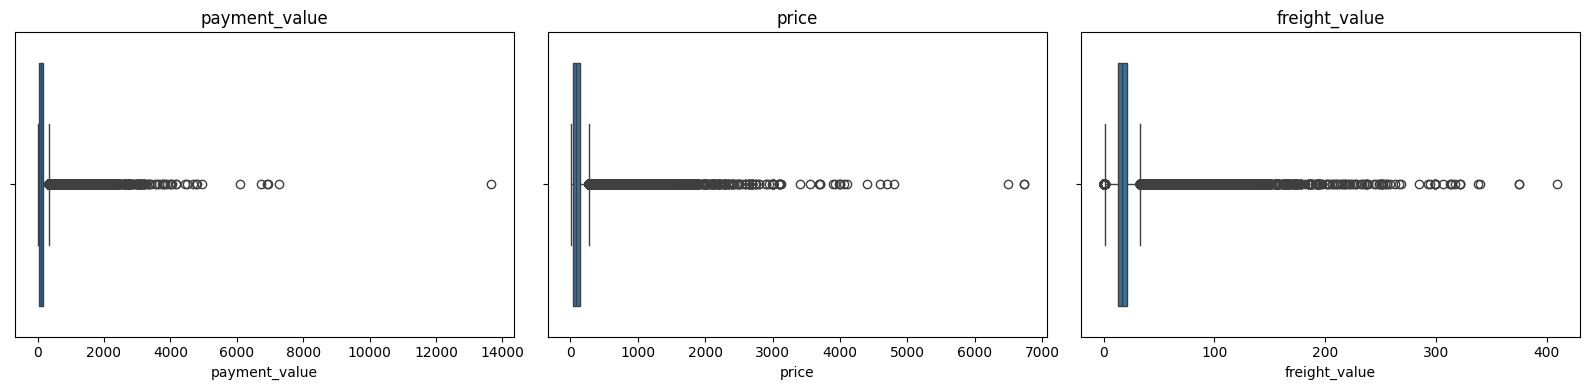

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=payments_df["payment_value"], ax=axes[0])
axes[0].set_title("payment_value")
sns.boxplot(x=order_items_df["price"], ax=axes[1])
axes[1].set_title("price")
sns.boxplot(x=order_items_df["freight_value"], ax=axes[2])
axes[2].set_title("freight_value")
plt.tight_layout()
plt.show()

In [44]:
payments_df.sort_values("payment_value", ascending=False).head(5)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08
34370,736e1922ae60d0d6a89247b851902527,1,boleto,1,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,1,credit_card,8,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,1,boleto,1,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,1,boleto,1,6726.66


In [45]:
orders_per_customer.sort_values(ascending=False).head(5).rename("jumlah_pesanan").to_frame()

,jumlah_pesanan
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
1b6c7548a2a1f9037c1fd3ddfed95f33,7
6469f99c1f9dfae7733b25662e7f1782,7
ca77025e7201e3b30c44b472ff346268,7


**Steps to Take:**
- Outlier pada `payment_value`, `price`, dan `freight_value` tidak dibuang karena tidak ada indikasi salah input; nilai tinggi tersebut bisa berasal dari produk mahal atau pesanan dengan banyak barang.
- Outlier pada jumlah pesanan per pelanggan tidak ditangani karena justru menjadi dasar perhitungan repeat rate dan Frequency.

**Insight:**
- `payment_value`, `price`, dan `freight_value` sangat condong ke kanan: sebagian besar transaksi bernilai kecil dan ada sedikit transaksi bernilai sangat besar (pembayaran tertinggi 13.664,08).
- Dengan metode IQR, outlier ditemukan pada 7.981 baris pembayaran (7,68%), 8.427 baris `price` (7,48%), dan 12.134 baris `freight_value` (10,77%). Outlier pada `payment_value` akan memengaruhi nilai Monetary (Pertanyaan 1) dan rata-rata nilai transaksi (Pertanyaan 2).
- Pada jumlah pesanan per pelanggan, Q1 dan Q3 sama-sama 1, sehingga semua 2.997 pelanggan (3,12%) yang memesan lebih dari sekali terhitung outlier. Ini sesuai dengan temuan awal bahwa repeat rate sangat rendah. Jumlah pesanan terbanyak oleh satu pelanggan adalah 17.

#### Identifying Out-of-Period Data problem

In [46]:
monthly_orders = orders_dt["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
monthly_orders.rename("jumlah_pesanan").to_frame().T

order_purchase_timestamp,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
jumlah_pesanan,4,324,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


In [47]:
in_period = orders_dt["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")
print("Rentang order_purchase_timestamp:", orders_dt["order_purchase_timestamp"].min(), "s.d.", orders_dt["order_purchase_timestamp"].max())
print("Pesanan di dalam periode Januari 2017 - Agustus 2018:", in_period.sum())
print("Pesanan di luar periode                            :", (~in_period).sum())
orders_dt.loc[~in_period, "order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index().rename("jumlah_pesanan").to_frame()

Rentang order_purchase_timestamp: 2016-09-04 21:15:19 s.d. 2018-10-17 17:30:18
Pesanan di dalam periode Januari 2017 - Agustus 2018: 99092
Pesanan di luar periode                            : 349


,jumlah_pesanan
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2018-09,16
2018-10,4


**Steps to Take:**
- Filter `orders` agar hanya berisi pesanan dengan `order_purchase_timestamp` dari 1 Januari 2017 sampai 31 Agustus 2018, lalu gunakan hasil filter ini untuk tabel lain.

**Insight:**
- Data pesanan mencakup September 2016 sampai Oktober 2018, tetapi data di luar Januari 2017 – Agustus 2018 sangat sedikit dan tidak lengkap (misalnya November 2016 tidak ada data dan Desember 2016 hanya 1 pesanan).
- Ada 349 pesanan di luar periode analisis yang perlu dibuang agar sesuai dengan cakupan keempat pertanyaan bisnis.

#### Ringkasan Hasil Assessing Data

| Jenis masalah | Tabel | Temuan | Berpengaruh ke | Penanganan |
|---|---|---|---|---|
| Missing value | orders | 160 `order_approved_at`, 1.783 `order_delivered_carrier_date`, 2.965 `order_delivered_customer_date` kosong (sebagian besar sesuai status) | Tidak langsung, kecuali jika memfilter berdasarkan status | Dibiarkan |
| Missing value | orders – payments / items | 1 pesanan tanpa pembayaran, 775 pesanan tanpa data barang | Pertanyaan 1, 2 | Drop (ikut filter periode dan status) |
| Invalid value | orders, order_items | Kolom tanggal masih bertipe teks | Pertanyaan 1, 3 | Ubah ke `datetime` |
| Invalid value | order_payments | 9 pembayaran bernilai 0, 3 `payment_type` = `not_defined` | Pertanyaan 1, 2 | Drop |
| Invalid value | order_payments | 2 cicilan bernilai 0 | Pertanyaan 2 | Imputation dengan modus (1) |
| Invalid value | geolocation | 42 koordinat di luar wilayah Brasil | Pertanyaan 4 | Drop |
| Duplicate data | orders, customers, order_payments, order_items | Tidak ada baris atau kunci duplikat | – | – |
| Duplicate data | geolocation | 261.831 baris duplikat | Pertanyaan 4 | Drop |
| Inaccurate value | orders | Urutan tanggal pengiriman tidak logis; status tidak sesuai dengan tanggal | Hanya jika memfilter berdasarkan status | Dibiarkan; pesanan `canceled` ikut terbuang dari data P1–P2 |
| Inaccurate value | payments vs items | 249 pesanan dengan selisih total pembayaran dan total barang lebih dari 1 | Pertanyaan 1, 2 | Pakai `payment_value` |
| Inconsistent value | customers | 250 pelanggan dengan lebih dari satu kode pos, 39 di antaranya berbeda negara bagian | Pertanyaan 4 | Pakai negara bagian dari pesanan terakhir |
| Inconsistent value | geolocation | Nama kota ditulis dengan beberapa cara; 8 kode pos di lebih dari satu negara bagian | Tidak berpengaruh (analisis per negara bagian) | Dibiarkan |
| Inconsistent value | order_payments | 2.246 pesanan dibayar dengan lebih dari satu metode | Pertanyaan 2 | Dibiarkan; P2 dihitung per pesanan dengan metode utama |
| Outlier | order_payments, order_items | Nilai transaksi sangat condong ke kanan (7,68% outlier pada `payment_value`) | Pertanyaan 1, 2 | Dibiarkan |
| Data di luar periode | orders | 349 pesanan di luar periode Januari 2017 – Agustus 2018 | Pertanyaan 1, 2, 3, 4 | Drop |
| Status pesanan | orders | 2.881 pesanan dalam periode tidak berstatus `delivered` | Pertanyaan 1, 2, 4 | P1, P2, P4 hanya `delivered`; P3 semua status |

### Cleaning Data

Keputusan penanganan data yang dipakai pada tahap ini:
- **Pertanyaan 1, 2, dan 4** hanya memakai pesanan berstatus `delivered`, karena hanya pesanan ini yang transaksinya benar-benar selesai. Pertanyaan 4 memakai segmen RFM dari Pertanyaan 1, sehingga datanya harus sama.
- **Pertanyaan 3** memakai pesanan dengan semua status, karena pesanan yang dibatalkan pun tetap menunjukkan kapan pelanggan sedang aktif berbelanja.
- Nilai Monetary dan nilai transaksi diambil dari `payment_value`, yaitu nilai yang benar-benar dibayar pelanggan.
- **Pertanyaan 2** dihitung per pesanan. Perbandingan nilai transaksi hanya memakai pesanan yang dibayar dengan kartu kredit, yaitu kelompok cicilan (lebih dari 1x) dibandingkan kelompok kartu kredit 1x.
- **Pertanyaan 4** memakai lokasi per negara bagian. Posisi tiap negara bagian di peta diambil dari median koordinat `geolocation` yang sudah bebas duplikat dan berada di dalam wilayah Brasil.
- Outlier tidak dibuang, dan kolom tanggal pengiriman dibiarkan apa adanya karena tidak dipakai.
- `order_items_df` hanya dipakai sebagai pembanding saat Assessing Data, sehingga tidak dibersihkan.

#### Fixing Invalid Value problem: tipe data kolom tanggal

In [48]:
datetime_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

In [49]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


**Insight:**
- Seluruh kolom tanggal di `orders_df` dan `shipping_limit_date` di `order_items_df` sekarang bertipe `datetime64`, sehingga bisa dipakai untuk menghitung Recency dan mengambil hari serta jam pembelian.

#### Fixing Out-of-Period Data problem

In [50]:
orders_period_df = orders_df[
    orders_df["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")
].copy()

print("Jumlah pesanan sebelum filter:", len(orders_df))
print("Jumlah pesanan sesudah filter:", len(orders_period_df))
print("Pesanan yang dibuang         :", len(orders_df) - len(orders_period_df))
print("Rentang order_purchase_timestamp:", orders_period_df["order_purchase_timestamp"].min(), "s.d.", orders_period_df["order_purchase_timestamp"].max())

Jumlah pesanan sebelum filter: 99441
Jumlah pesanan sesudah filter: 99092
Pesanan yang dibuang         : 349
Rentang order_purchase_timestamp: 2017-01-05 11:56:06 s.d. 2018-08-31 16:13:44


**Insight:**
- 349 pesanan di luar Januari 2017 – Agustus 2018 sudah dibuang, sehingga tersisa 99.092 pesanan.
- Pesanan tanpa data pembayaran (dibeli September 2016) ikut terbuang pada langkah ini.

#### Fixing Order Status problem: memisahkan data untuk tiap pertanyaan

In [51]:
orders_period_df["order_status"].value_counts()

order_status
delivered      96211
shipped         1097
unavailable      602
canceled         580
processing       299
invoiced         296
created            5
approved           2
Name: count, dtype: int64

In [52]:
orders_all_status_df = orders_period_df.copy()
orders_delivered_df = orders_period_df[orders_period_df["order_status"] == "delivered"].copy()

print("Pesanan untuk Pertanyaan 3 (semua status)          :", len(orders_all_status_df))
print("Pesanan untuk Pertanyaan 1, 2, dan 4 (delivered)   :", len(orders_delivered_df))
print("Pesanan non-delivered yang tidak dipakai di P1, P2, P4:", len(orders_period_df) - len(orders_delivered_df))

Pesanan untuk Pertanyaan 3 (semua status)          : 99092
Pesanan untuk Pertanyaan 1, 2, dan 4 (delivered)   : 96211
Pesanan non-delivered yang tidak dipakai di P1, P2, P4: 2881


Pengecekan masalah yang ikut terselesaikan oleh filter `delivered`:

In [53]:
pd.Series({
    "pesanan tanpa data pembayaran": (~orders_delivered_df["order_id"].isin(payments_df["order_id"])).sum(),
    "pesanan tanpa data barang": (~orders_delivered_df["order_id"].isin(order_items_df["order_id"])).sum(),
    "pesanan canceled dengan tanggal diterima": (orders_delivered_df["order_status"] == "canceled").sum(),
}, name="jumlah_pesanan").to_frame()

,jumlah_pesanan
pesanan tanpa data pembayaran,0
pesanan tanpa data barang,0
pesanan canceled dengan tanggal diterima,0


In [54]:
orders_delivered_df.isna().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Pelanggan yang dipakai untuk Pertanyaan 1 dan 4 adalah pelanggan dari pesanan `delivered`:

In [55]:
customers_clean_df = customers_df[customers_df["customer_id"].isin(orders_delivered_df["customer_id"])].copy()

print("Jumlah customer_id       :", customers_clean_df["customer_id"].nunique())
print("Jumlah customer_unique_id:", customers_clean_df["customer_unique_id"].nunique())

Jumlah customer_id       : 96211
Jumlah customer_unique_id: 93104


**Insight:**
- Pertanyaan 3 memakai 99.092 pesanan dari semua status, sedangkan Pertanyaan 1, 2, dan 4 memakai 96.211 pesanan berstatus `delivered`.
- Setelah filter `delivered`, semua pesanan punya data pembayaran dan data barang. Pesanan `canceled` yang punya tanggal diterima juga ikut terbuang.
- Masih ada missing value di `order_approved_at` (14), `order_delivered_carrier_date` (2), dan `order_delivered_customer_date` (8). Missing value ini dibiarkan karena kolom tersebut tidak dipakai, dan mengisinya berarti mengarang tanggal kejadian.
- Ada 93.104 pelanggan unik (`customer_unique_id`) dari pesanan `delivered` yang akan dipakai untuk repeat rate, RFM, dan sebaran wilayah.

#### Fixing Invalid Value problem pada `order_payments`

In [56]:
payments_clean_df = payments_df[payments_df["order_id"].isin(orders_delivered_df["order_id"])].copy()
print("Baris pembayaran dari pesanan delivered:", len(payments_clean_df))

Baris pembayaran dari pesanan delivered: 100473


**Drop** pembayaran bernilai 0. Baris `not_defined` dan dua baris `voucher` sudah terbuang bersama pesanan non-`delivered`, sehingga yang tersisa adalah pembayaran `voucher` bernilai 0 berikut:

In [57]:
payments_clean_df[payments_clean_df["payment_value"] <= 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


In [58]:
payments_clean_df = payments_clean_df[payments_clean_df["payment_value"] > 0]
print("Baris pembayaran setelah drop nilai 0:", len(payments_clean_df))

Baris pembayaran setelah drop nilai 0: 100469


**Imputation** `payment_installments` yang bernilai 0 dengan modus kolom tersebut:

In [59]:
payments_clean_df[payments_clean_df["payment_installments"] < 1]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [60]:
installments_mode = payments_clean_df["payment_installments"].mode()[0]
print("Modus payment_installments:", installments_mode)

payments_clean_df.loc[payments_clean_df["payment_installments"] < 1, "payment_installments"] = installments_mode

Modus payment_installments: 1


Pengecekan hasil cleaning `payments_clean_df`:

In [61]:
pd.Series({
    "payment_value <= 0": (payments_clean_df["payment_value"] <= 0).sum(),
    "payment_installments < 1": (payments_clean_df["payment_installments"] < 1).sum(),
    "payment_type not_defined": (payments_clean_df["payment_type"] == "not_defined").sum(),
    "pesanan delivered tanpa pembayaran": (~orders_delivered_df["order_id"].isin(payments_clean_df["order_id"])).sum(),
}, name="jumlah").to_frame()

,jumlah
payment_value <= 0,0
payment_installments < 1,0
payment_type not_defined,0
pesanan delivered tanpa pembayaran,0


In [62]:
payments_clean_df["payment_type"].value_counts()

payment_type
credit_card    74376
boleto         19140
voucher         5469
debit_card      1484
Name: count, dtype: int64

**Insight:**
- Dari 9 pembayaran bernilai 0, 5 sudah terbuang bersama pesanan non-`delivered` (3 `not_defined` dan 2 `voucher`). Sisa 4 pembayaran `voucher` bernilai 0 di-drop.
- 2 baris kartu kredit dengan `payment_installments` = 0 diisi dengan modus, yaitu 1. Kedua baris ini kini dihitung sebagai pembayaran sekali bayar.
- `payments_clean_df` tidak lagi memiliki nilai pembayaran 0, cicilan 0, atau metode `not_defined`, dan semua pesanan `delivered` tetap punya data pembayaran.

#### Fixing Duplicate Data dan Invalid Value problem pada `geolocation`

**Drop** baris duplikat:

In [63]:
geolocation_clean_df = geolocation_df.drop_duplicates()
print("Baris sebelum drop duplikat:", len(geolocation_df))
print("Baris sesudah drop duplikat:", len(geolocation_clean_df))

Baris sebelum drop duplikat: 1000163
Baris sesudah drop duplikat: 738332


**Drop** koordinat di luar wilayah Brasil:

In [64]:
inside_brazil = (
    geolocation_clean_df["geolocation_lat"].between(-33.75, 5.27)
    & geolocation_clean_df["geolocation_lng"].between(-73.99, -34.79)
)
geolocation_clean_df = geolocation_clean_df[inside_brazil].copy()
print("Baris sesudah drop koordinat di luar Brasil:", len(geolocation_clean_df))

Baris sesudah drop koordinat di luar Brasil: 738299


Posisi tiap negara bagian di peta diambil dari **median** koordinat, karena median tidak mudah tergeser oleh koordinat yang meleset:

In [65]:
state_location_df = (
    geolocation_clean_df.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]]
    .median()
    .rename_axis("customer_state")
    .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"})
)
print("Jumlah negara bagian dengan koordinat:", len(state_location_df))
state_location_df.head()

Jumlah negara bagian dengan koordinat: 27


,lat,lng
customer_state,,
AC,-9.961648,-67.831102
AL,-9.636258,-35.756508
AM,-3.090152,-60.010616
AP,0.031209,-51.073509
BA,-12.948131,-38.998427


**Insight:**
- 261.831 baris duplikat dan 42 koordinat di luar Brasil sudah dibuang dari `geolocation_clean_df`.
- `state_location_df` berisi satu titik koordinat untuk setiap negara bagian (27 negara bagian). Titik ini mewakili pusat sebaran data kode pos, yang umumnya berada di sekitar kota-kota besar, bukan pusat geografis wilayahnya.

#### Ringkasan hasil Cleaning Data

In [66]:
pd.DataFrame({
    "orders_all_status_df": {"jumlah_baris": len(orders_all_status_df), "dipakai_untuk": "Pertanyaan 3"},
    "orders_delivered_df": {"jumlah_baris": len(orders_delivered_df), "dipakai_untuk": "Pertanyaan 1, 2, dan 4"},
    "customers_clean_df": {"jumlah_baris": len(customers_clean_df), "dipakai_untuk": "Pertanyaan 1 dan 4"},
    "payments_clean_df": {"jumlah_baris": len(payments_clean_df), "dipakai_untuk": "Pertanyaan 1 dan 2"},
    "state_location_df": {"jumlah_baris": len(state_location_df), "dipakai_untuk": "Pertanyaan 4"},
}).T

,jumlah_baris,dipakai_untuk
orders_all_status_df,99092,Pertanyaan 3
orders_delivered_df,96211,"Pertanyaan 1, 2, dan 4"
customers_clean_df,96211,Pertanyaan 1 dan 4
payments_clean_df,100469,Pertanyaan 1 dan 2
state_location_df,27,Pertanyaan 4


## Exploratory Data Analysis (EDA)

### Explore Tabel Gabungan untuk Analisis

Menggabungkan pesanan `delivered` dengan data pelanggan, sehingga setiap pesanan punya `customer_unique_id` dan `customer_state`:

In [67]:
orders_customers_df = orders_delivered_df.merge(customers_clean_df, on="customer_id", how="left")
print("Jumlah pesanan                   :", len(orders_customers_df))
print("Pesanan tanpa customer_unique_id :", orders_customers_df["customer_unique_id"].isna().sum())
orders_customers_df.head()

Jumlah pesanan                   : 96211
Pesanan tanpa customer_unique_id : 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


Membuat ringkasan pembayaran per pesanan sesuai aturan Pertanyaan 2:
- `total_payment`: total `payment_value` pesanan.
- `main_payment_type`: metode dengan nilai pembayaran terbesar dalam pesanan.
- `credit_card_installments`: jumlah cicilan kartu kredit terbesar dalam pesanan (kosong jika tidak memakai kartu kredit).
- `credit_card_group`: hasil binning `credit_card_installments` menjadi **Kartu kredit 1x** (cicilan = 1) dan **Cicilan** (cicilan > 1).

In [68]:
main_payment_type = (
    payments_clean_df.groupby(["order_id", "payment_type"], as_index=False)["payment_value"].sum()
    .sort_values(["order_id", "payment_value", "payment_type"], ascending=[True, False, True])
    .drop_duplicates("order_id")
    .set_index("order_id")["payment_type"]
)

credit_card_installments = (
    payments_clean_df[payments_clean_df["payment_type"] == "credit_card"]
    .groupby("order_id")["payment_installments"]
    .max()
)

order_payments_df = pd.DataFrame({
    "total_payment": payments_clean_df.groupby("order_id")["payment_value"].sum(),
    "main_payment_type": main_payment_type,
    "credit_card_installments": credit_card_installments,
})
order_payments_df["credit_card_group"] = pd.cut(
    order_payments_df["credit_card_installments"],
    bins=[0, 1, order_payments_df["credit_card_installments"].max()],
    labels=["Kartu kredit 1x", "Cicilan"],
)
order_payments_df.head()

,total_payment,main_payment_type,credit_card_installments,credit_card_group
order_id,,,,
00010242fe8c5a6d1ba2dd792cb16214,72.19,credit_card,2.0,Cicilan
00018f77f2f0320c557190d7a144bdd3,259.83,credit_card,3.0,Cicilan
000229ec398224ef6ca0657da4fc703e,216.87,credit_card,5.0,Cicilan
00024acbcdf0a6daa1e931b038114c75,25.78,credit_card,2.0,Cicilan
00042b26cf59d7ce69dfabb4e55b4fd9,218.04,credit_card,3.0,Cicilan


Tabel gabungan utama (`main_df`) untuk Pertanyaan 1, 2, dan 4:

In [69]:
main_df = orders_customers_df.merge(order_payments_df, left_on="order_id", right_index=True, how="left")
main_df = main_df[[
    "order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
    "total_payment", "main_payment_type", "credit_card_installments", "credit_card_group",
]]
print("Jumlah baris:", len(main_df))
main_df.isna().sum()

Jumlah baris: 96211


order_id                        0
customer_unique_id              0
customer_state                  0
order_purchase_timestamp        0
total_payment                   0
main_payment_type               0
credit_card_installments    22116
credit_card_group           22116
dtype: int64

**Insight:**
- `main_df` berisi 96.211 pesanan `delivered` (satu baris per pesanan) beserta pelanggan, negara bagian, dan ringkasan pembayarannya.
- Tidak ada missing value pada kolom pelanggan, negara bagian, dan pembayaran. Kolom `credit_card_installments` dan `credit_card_group` kosong untuk 22.116 pesanan yang tidak memakai kartu kredit, dan ini memang sesuai aturan.
- Pesanan yang memakai kartu kredit berjumlah 74.095 (96.211 − 22.116). Pesanan inilah yang dipakai untuk membandingkan cicilan dan kartu kredit 1x di Pertanyaan 2.

### Explore Pelanggan dan Pembelian Ulang (Pertanyaan 1)

In [70]:
customer_orders_df = main_df.groupby("customer_unique_id").agg(
    jumlah_pesanan=("order_id", "nunique"),
    total_belanja=("total_payment", "sum"),
)
customer_orders_df.describe()

,jumlah_pesanan,total_belanja
count,93104.000000,93104.000000
mean,1.033371,165.147313
std,0.209012,226.381578
min,1.000000,9.590000
25%,1.000000,63.040000
50%,1.000000,107.780000
75%,1.000000,182.495000
max,15.000000,13664.080000


Sebaran jumlah pesanan per pelanggan:

In [71]:
order_count_df = customer_orders_df.groupby("jumlah_pesanan").agg(jumlah_pelanggan=("total_belanja", "size"))
order_count_df["persen_pelanggan"] = (order_count_df["jumlah_pelanggan"] / order_count_df["jumlah_pelanggan"].sum() * 100).round(2)
order_count_df

,jumlah_pelanggan,persen_pelanggan
jumlah_pesanan,,
1,90315,97.00
2,2562,2.75
3,180,0.19
4,28,0.03
5,9,0.01
6,5,0.01
7,3,0.00
9,1,0.00
15,1,0.00


In [72]:
repeat_customers = (customer_orders_df["jumlah_pesanan"] > 1).sum()
total_customers = len(customer_orders_df)

print("Jumlah pelanggan           :", total_customers)
print("Pelanggan belanja ulang    :", repeat_customers)
print("Repeat rate                : {:.2f}%".format(repeat_customers / total_customers * 100))

Jumlah pelanggan           : 93104
Pelanggan belanja ulang    : 2789
Repeat rate                : 3.00%


Perbandingan pelanggan sekali beli dan pelanggan yang belanja ulang:

In [73]:
customer_orders_df["kategori_pelanggan"] = pd.cut(
    customer_orders_df["jumlah_pesanan"],
    bins=[0, 1, customer_orders_df["jumlah_pesanan"].max()],
    labels=["Sekali beli", "Belanja ulang"],
)

customer_type_df = customer_orders_df.groupby("kategori_pelanggan", observed=True).agg(
    jumlah_pelanggan=("jumlah_pesanan", "size"),
    jumlah_pesanan=("jumlah_pesanan", "sum"),
    total_belanja=("total_belanja", "sum"),
    rata_rata_belanja=("total_belanja", "mean"),
    median_belanja=("total_belanja", "median"),
)
customer_type_df["persen_pelanggan"] = (customer_type_df["jumlah_pelanggan"] / customer_type_df["jumlah_pelanggan"].sum() * 100).round(2)
customer_type_df["persen_pendapatan"] = (customer_type_df["total_belanja"] / customer_type_df["total_belanja"].sum() * 100).round(2)
customer_type_df.round(2)

,jumlah_pelanggan,jumlah_pesanan,total_belanja,rata_rata_belanja,median_belanja,persen_pelanggan,persen_pendapatan
kategori_pelanggan,,,,,,,
Sekali beli,90315,90315,14515120.88,160.72,105.38,97.0,94.4
Belanja ulang,2789,5896,860754.56,308.62,225.63,3.0,5.6


**Insight:**
- Dari 93.104 pelanggan, hanya 2.789 yang belanja lebih dari sekali, sehingga **repeat rate selama Januari 2017 – Agustus 2018 hanya 3,00%**.
- 97% pelanggan hanya belanja 1 kali dan 2,75% belanja 2 kali. Hanya 227 pelanggan (0,24%) yang belanja 3 kali atau lebih, dengan jumlah pesanan terbanyak 15.
- Pelanggan yang belanja ulang rata-rata menghabiskan 308,62 per orang, hampir 2 kali lipat pelanggan sekali beli (160,72). Mediannya juga hampir 2 kali lipat (225,63 vs 105,38).
- Meski nilainya lebih besar per orang, pelanggan yang belanja ulang hanya menyumbang 5,6% total pendapatan karena jumlahnya sangat sedikit. Pendapatan hampir seluruhnya (94,4%) bergantung pada pelanggan baru yang belanja sekali, sehingga meningkatkan retensi berpotensi besar menambah pendapatan.

### Explore Metode Pembayaran (Pertanyaan 2)

Proporsi metode pembayaran utama per pesanan:

In [74]:
payment_method_df = main_df.groupby("main_payment_type").agg(
    jumlah_pesanan=("order_id", "nunique"),
    total_nilai=("total_payment", "sum"),
    rata_rata_nilai=("total_payment", "mean"),
).sort_values("jumlah_pesanan", ascending=False)
payment_method_df["persen_pesanan"] = (payment_method_df["jumlah_pesanan"] / payment_method_df["jumlah_pesanan"].sum() * 100).round(2)
payment_method_df.round(2)

,jumlah_pesanan,total_nilai,rata_rata_nilai,persen_pesanan
main_payment_type,,,,
credit_card,72580,12057213.16,166.12,75.44
boleto,19140,2762300.80,144.32,19.89
voucher,3009,348232.09,115.73,3.13
debit_card,1482,208129.39,140.44,1.54


Perbandingan nilai transaksi pesanan kartu kredit cicilan dan kartu kredit 1x:

In [75]:
credit_card_df = main_df[main_df["credit_card_group"].notna()]

credit_card_group_df = credit_card_df.groupby("credit_card_group", observed=True).agg(
    jumlah_pesanan=("order_id", "nunique"),
    rata_rata_nilai=("total_payment", "mean"),
    median_nilai=("total_payment", "median"),
    min_nilai=("total_payment", "min"),
    max_nilai=("total_payment", "max"),
    total_nilai=("total_payment", "sum"),
)
credit_card_group_df["persen_pesanan"] = (credit_card_group_df["jumlah_pesanan"] / credit_card_group_df["jumlah_pesanan"].sum() * 100).round(2)
credit_card_group_df.round(2)

,jumlah_pesanan,rata_rata_nilai,median_nilai,min_nilai,max_nilai,total_nilai,persen_pesanan
credit_card_group,,,,,,,
Kartu kredit 1x,24595,101.14,72.08,9.59,13664.08,2487435.45,33.19
Cicilan,49500,197.19,134.52,20.03,6929.31,9760718.27,66.81


Nilai transaksi berdasarkan jumlah cicilan:

In [76]:
installments_df = credit_card_df.groupby(credit_card_df["credit_card_installments"].astype(int)).agg(
    jumlah_pesanan=("order_id", "nunique"),
    rata_rata_nilai=("total_payment", "mean"),
    median_nilai=("total_payment", "median"),
)
installments_df.round(2)

,jumlah_pesanan,rata_rata_nilai,median_nilai
credit_card_installments,,,
1,24595,101.14,72.08
2,12001,128.35,111.42
3,10099,143.80,112.32
4,6842,164.78,117.58
5,5067,183.63,126.92
6,3777,210.45,139.15
7,1550,187.85,139.95
8,4117,308.29,212.56
9,615,198.93,105.08


Persentase pesanan kartu kredit yang memakai cicilan berdasarkan rentang nilai transaksi. Nilai transaksi dibagi menjadi 10 rentang dengan jumlah pesanan yang sama menggunakan `pd.qcut`:

In [77]:
value_bins = pd.qcut(credit_card_df["total_payment"], q=10)

installment_share_df = credit_card_df.groupby(value_bins, observed=True).agg(
    jumlah_pesanan=("order_id", "nunique"),
    pesanan_cicilan=("credit_card_group", lambda s: (s == "Cicilan").sum()),
    rata_rata_jumlah_cicilan=("credit_card_installments", "mean"),
)
installment_share_df["persen_cicilan"] = installment_share_df["pesanan_cicilan"] / installment_share_df["jumlah_pesanan"] * 100
installment_share_df.index = [f"{interval.left:.2f} - {interval.right:.2f}" for interval in installment_share_df.index]
installment_share_df.index.name = "rentang_nilai_transaksi"
installment_share_df.round(2)

,jumlah_pesanan,pesanan_cicilan,rata_rata_jumlah_cicilan,persen_cicilan
rentang_nilai_transaksi,,,,
9.59 - 41.01,7417,2515,1.55,33.91
41.01 - 56.78,7426,3528,2.12,47.51
56.78 - 71.53,7393,4002,2.48,54.13
71.53 - 88.65,7406,4299,2.84,58.05
88.65 - 108.81,7410,4905,3.30,66.19
108.81 - 133.75,7407,5335,3.48,72.03
133.75 - 163.68,7413,5802,3.77,78.27
163.68 - 208.60,7404,6119,4.21,82.64
208.60 - 315.96,7409,6335,4.90,85.50


**Insight:**
- Kartu kredit adalah metode pembayaran utama yang paling banyak dipakai, yaitu pada 75,44% pesanan (72.580 pesanan). Urutan berikutnya adalah boleto (19,89%), voucher (3,13%), dan kartu debit (1,54%).
- Pesanan dengan kartu kredit juga memiliki rata-rata nilai transaksi tertinggi (166,12), lebih tinggi daripada boleto (144,32) dan kartu debit (140,44).
- Dari 74.095 pesanan kartu kredit, 66,81% dibayar dengan cicilan dan 33,19% dibayar 1x.
- **Rata-rata nilai transaksi pesanan cicilan (197,19) hampir 2 kali lipat pesanan kartu kredit 1x (101,14).** Median juga menunjukkan pola yang sama (134,52 vs 72,08), sehingga perbedaan ini bukan hanya karena segelintir transaksi bernilai sangat besar. Transaksi terbesar (13.664,08) justru ada di kelompok 1x.
- Rata-rata nilai transaksi cenderung naik seiring jumlah cicilan: 128,35 untuk 2x, 183,63 untuk 5x, dan 414,21 untuk 10x. Polanya tidak selalu naik (misalnya 9x lebih rendah dari 8x). Cicilan di atas 12x jumlah pesanannya sangat sedikit (paling banyak 72 pesanan), sehingga angkanya kurang bisa diandalkan.
- Semakin besar nilai transaksi, semakin banyak pesanan kartu kredit yang memakai cicilan: dari 33,91% pada rentang nilai terendah (9,59–41,01) menjadi 89,88% pada rentang tertinggi (di atas 315,96). Rata-rata jumlah cicilan juga naik dari 1,55x menjadi 6,35x.

### Explore Waktu Belanja (Pertanyaan 3)

In [78]:
day_names = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

purchase_time_df = orders_all_status_df[["order_id", "order_purchase_timestamp"]].copy()
purchase_time_df["hari"] = pd.Categorical(
    purchase_time_df["order_purchase_timestamp"].dt.dayofweek.map(dict(enumerate(day_names))),
    categories=day_names,
    ordered=True,
)
purchase_time_df["jam"] = purchase_time_df["order_purchase_timestamp"].dt.hour
purchase_time_df.head()

,order_id,order_purchase_timestamp,hari,jam
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,Senin,10
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,Selasa,20
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,Rabu,8
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,Sabtu,19
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,Selasa,21


Jumlah pesanan per hari:

In [79]:
orders_by_day_df = purchase_time_df.groupby("hari", observed=True).agg(jumlah_pesanan=("order_id", "nunique"))
orders_by_day_df["persen_pesanan"] = (orders_by_day_df["jumlah_pesanan"] / orders_by_day_df["jumlah_pesanan"].sum() * 100).round(2)
orders_by_day_df

,jumlah_pesanan,persen_pesanan
hari,,
Senin,16141,16.29
Selasa,15896,16.04
Rabu,15501,15.64
Kamis,14704,14.84
Jumat,14075,14.20
Sabtu,10843,10.94
Minggu,11932,12.04


Jumlah pesanan per jam:

In [80]:
orders_by_hour_df = purchase_time_df.groupby("jam").agg(jumlah_pesanan=("order_id", "nunique"))
orders_by_hour_df["persen_pesanan"] = (orders_by_hour_df["jumlah_pesanan"] / orders_by_hour_df["jumlah_pesanan"].sum() * 100).round(2)
orders_by_hour_df.T

jam,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
jumlah_pesanan,2387.00,1168.00,506.00,272.00,203.0,188.00,502.00,1225.00,2953.00,4765.00,6151.00,6554.00,5973.00,6494.00,6547.00,6426.00,6655.00,6130.00,5753.00,5971.00,6178.00,6201.00,5782.00,4108.00
persen_pesanan,2.41,1.18,0.51,0.27,0.2,0.19,0.51,1.24,2.98,4.81,6.21,6.61,6.03,6.55,6.61,6.48,6.72,6.19,5.81,6.03,6.23,6.26,5.83,4.15


Jumlah pesanan per hari dan jam:

In [81]:
day_hour_df = purchase_time_df.pivot_table(
    index="hari", columns="jam", values="order_id", aggfunc="nunique", observed=True
)
day_hour_df

jam,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
hari,,,,,,,,,,,,,,,,,,,,,,,,
Senin,326,134,65,36,19,22,69,158,478,777,1031,1074,968,1026,1093,1072,1089,988,924,945,1027,1116,987,717
Selasa,306,158,80,28,29,24,71,223,522,861,964,1053,896,1035,1119,1039,1074,965,874,919,985,1023,961,687
Rabu,396,178,81,33,33,27,93,210,512,827,1042,1056,915,1027,1046,980,1039,961,850,847,900,961,873,614
Kamis,353,167,74,39,31,28,85,218,500,754,980,958,978,978,974,926,1073,906,780,824,835,840,854,549
Jumat,425,216,71,49,40,36,97,206,490,766,946,987,853,1002,956,977,972,814,722,781,738,723,698,510
Sabtu,315,174,66,43,24,24,53,105,246,431,658,708,689,705,675,718,696,699,708,756,726,650,546,428
Minggu,266,141,69,44,27,27,34,105,205,349,530,718,674,721,684,714,712,797,895,899,967,888,863,603


**Clustering dengan binning:** jam pembelian dikelompokkan menjadi lima kelompok waktu menggunakan `pd.cut`:

| Kelompok waktu | Jam |
|---|---|
| Dini hari | 00.00–04.59 |
| Pagi | 05.00–10.59 |
| Siang | 11.00–14.59 |
| Sore | 15.00–17.59 |
| Malam | 18.00–23.59 |

Karena panjang tiap kelompok berbeda, kolom `rata_rata_pesanan_per_jam` dipakai agar perbandingannya adil.

In [82]:
time_bins = [-1, 4, 10, 14, 17, 23]
time_labels = ["Dini hari", "Pagi", "Siang", "Sore", "Malam"]

purchase_time_df["kelompok_waktu"] = pd.cut(purchase_time_df["jam"], bins=time_bins, labels=time_labels)
hours_per_group = pd.cut(pd.Series(range(24)), bins=time_bins, labels=time_labels).value_counts()

orders_by_time_group_df = purchase_time_df.groupby("kelompok_waktu", observed=True).agg(
    jumlah_pesanan=("order_id", "nunique")
)
orders_by_time_group_df["jumlah_jam"] = hours_per_group
orders_by_time_group_df["persen_pesanan"] = (orders_by_time_group_df["jumlah_pesanan"] / orders_by_time_group_df["jumlah_pesanan"].sum() * 100).round(2)
orders_by_time_group_df["rata_rata_pesanan_per_jam"] = (orders_by_time_group_df["jumlah_pesanan"] / orders_by_time_group_df["jumlah_jam"]).round(0)
orders_by_time_group_df

,jumlah_pesanan,jumlah_jam,persen_pesanan,rata_rata_pesanan_per_jam
kelompok_waktu,,,,
Dini hari,4536,5,4.58,907.0
Pagi,15784,6,15.93,2631.0
Siang,25568,4,25.80,6392.0
Sore,19211,3,19.39,6404.0
Malam,33993,6,34.30,5666.0


**Insight:**
- Senin (16,29%) dan Selasa (16,04%) adalah hari dengan pesanan terbanyak, lalu jumlahnya turun perlahan sampai Jumat. Sabtu adalah hari paling sepi (10,94%), diikuti Minggu (12,04%).
- Per jam, pesanan mulai naik tajam pukul 08.00 dan bertahan tinggi dari pukul 10.00 sampai 22.59 (masing-masing sekitar 5.750–6.650 pesanan). Puncaknya pukul 16.00 (6.655 pesanan), sedangkan pukul 05.00 paling sepi (188 pesanan).
- Pola hari kerja dan akhir pekan berbeda. Pada hari kerja, pesanan ramai sejak pukul 10.00. Pada hari Minggu, pesanan justru paling ramai pada malam hari (pukul 18.00–22.59), lebih tinggi daripada siang harinya.
- Hasil binning menunjukkan kelompok **Malam** menyumbang pesanan terbanyak secara total (34,30%) karena rentangnya 6 jam. Namun jika dilihat dari rata-rata per jam, **Sore** (6.404 pesanan per jam) dan **Siang** (6.392) adalah waktu paling padat, diikuti Malam (5.666). Pagi (2.631) dan Dini hari (907) jauh lebih sepi.

### Explore Sebaran Pelanggan per Negara Bagian (Pertanyaan 4)

Pelanggan yang tercatat di lebih dari satu negara bagian diberi lokasi sesuai negara bagian pada pesanan terakhirnya:

In [83]:
customer_state_df = (
    main_df.sort_values("order_purchase_timestamp")
    .drop_duplicates("customer_unique_id", keep="last")
    .set_index("customer_unique_id")["customer_state"]
)
print("Jumlah pelanggan dengan lokasi:", customer_state_df.size)

Jumlah pelanggan dengan lokasi: 93104


In [84]:
state_customers_df = customer_orders_df.join(customer_state_df).groupby("customer_state").agg(
    jumlah_pelanggan=("jumlah_pesanan", "size"),
    pelanggan_belanja_ulang=("jumlah_pesanan", lambda s: (s > 1).sum()),
    total_belanja=("total_belanja", "sum"),
    rata_rata_belanja=("total_belanja", "mean"),
).sort_values("jumlah_pelanggan", ascending=False)
state_customers_df["persen_pelanggan"] = (state_customers_df["jumlah_pelanggan"] / state_customers_df["jumlah_pelanggan"].sum() * 100).round(2)
state_customers_df["repeat_rate"] = (state_customers_df["pelanggan_belanja_ulang"] / state_customers_df["jumlah_pelanggan"] * 100).round(2)
state_customers_df.round(2)

,jumlah_pelanggan,pelanggan_belanja_ulang,total_belanja,rata_rata_belanja,persen_pelanggan,repeat_rate
customer_state,,,,,,
SP,39059,1220,5758768.07,147.44,41.95,3.12
RJ,11877,389,2046720.21,172.33,12.76,3.28
MG,10963,318,1813972.83,165.46,11.78,2.90
RS,5150,158,858988.35,166.79,5.53,3.07
PR,4747,138,778268.41,163.95,5.10,2.91
SC,3438,93,592392.73,172.31,3.69,2.71
BA,3153,88,590672.98,187.34,3.39,2.79
DF,2010,58,344050.09,171.17,2.16,2.89
ES,1925,57,316835.04,164.59,2.07,2.96


Pengecekan bahwa semua negara bagian pelanggan punya koordinat untuk peta:

In [85]:
state_customers_df.join(state_location_df)[["jumlah_pelanggan", "lat", "lng"]].isna().sum()

jumlah_pelanggan    0
lat                 0
lng                 0
dtype: int64

**Insight:**
- Pelanggan sangat terpusat di wilayah tenggara Brasil: São Paulo (SP) 41,95%, Rio de Janeiro (RJ) 12,76%, dan Minas Gerais (MG) 11,78%. Ketiganya mencakup sekitar 66,5% dari seluruh pelanggan.
- Negara bagian di wilayah utara memiliki pelanggan paling sedikit, misalnya Roraima (RR) 39 pelanggan, Amapá (AP) 66 pelanggan, dan Acre (AC) 76 pelanggan.
- Repeat rate di hampir semua negara bagian sama rendahnya, yaitu sekitar 2–3,4%. Angka yang lebih tinggi seperti AC (5,26%) dan RO (4,33%) berasal dari jumlah pelanggan yang sangat kecil (4 dari 76 dan 10 dari 231), sehingga kurang bisa diandalkan. Masalah retensi terjadi merata di semua wilayah, bukan hanya di wilayah tertentu.
- Rata-rata belanja per pelanggan justru paling rendah di SP (147,44) dan lebih tinggi di wilayah yang jauh dari tenggara, misalnya PB (274,35) dan AC (257,71). Kemungkinan karena ongkos kirim ke wilayah tersebut lebih mahal, tetapi hal ini tidak dianalisis lebih lanjut.
- Semua negara bagian sudah memiliki koordinat di `state_location_df`. Jumlah pelanggan At Risk dan Lost per negara bagian akan dihitung di bagian Analisis Lanjutan setelah segmen RFM terbentuk.

## Visualization & Explanatory Analysis

Pengaturan tampilan grafik yang dipakai di seluruh bagian ini:
- Bar yang ingin disorot berwarna biru, sedangkan bar lainnya abu-abu.
- Grafik dengan dua ukuran memakai biru dan oranye, dilengkapi legenda.
- Angka ditulis dengan format Indonesia (titik sebagai pemisah ribuan, koma sebagai desimal).

In [86]:
HIGHLIGHT = "#2a78d6"
SECOND = "#eb6834"
MUTED = "#c9c8c2"
TEXT = "#52514e"
GRID = "#e6e5e0"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

sns.set_theme(style="white")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": TEXT,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
})


def format_number(value, decimals=0):
    text = f"{np.round(value, decimals):,.{decimals}f}"
    return text.replace(",", "_").replace(".", ",").replace("_", ".")


thousands_formatter = mticker.FuncFormatter(lambda value, _: format_number(value))

payment_type_labels = {
    "credit_card": "Kartu kredit",
    "boleto": "Boleto",
    "voucher": "Voucher",
    "debit_card": "Kartu debit",
}

### Pertanyaan 1: Berapa persentase pelanggan yang melakukan pembelian ulang selama Januari 2017 – Agustus 2018?

Segmentasi RFM untuk bagian kedua Pertanyaan 1 ada di bagian **Analisis Lanjutan**.

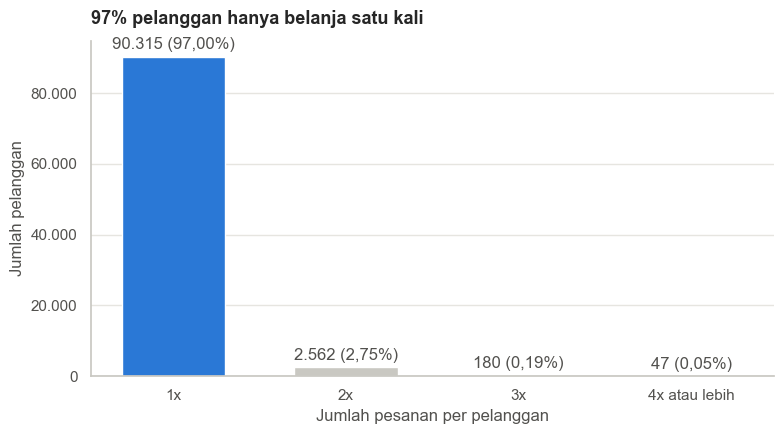

In [87]:
order_bins = pd.cut(
    customer_orders_df["jumlah_pesanan"],
    bins=[0, 1, 2, 3, customer_orders_df["jumlah_pesanan"].max()],
    labels=["1x", "2x", "3x", "4x atau lebih"],
)
order_bins_df = customer_orders_df.groupby(order_bins, observed=True).size().rename("jumlah_pelanggan").to_frame()
order_bins_df["persen"] = order_bins_df["jumlah_pelanggan"] / order_bins_df["jumlah_pelanggan"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    order_bins_df.index.astype(str),
    order_bins_df["jumlah_pelanggan"],
    color=[HIGHLIGHT, MUTED, MUTED, MUTED],
    width=0.6,
)
ax.bar_label(
    bars,
    labels=[f"{format_number(n)} ({format_number(p, 2)}%)" for n, p in zip(order_bins_df["jumlah_pelanggan"], order_bins_df["persen"])],
    padding=3,
    color=TEXT,
)
ax.set_title("97% pelanggan hanya belanja satu kali")
ax.set_xlabel("Jumlah pesanan per pelanggan")
ax.set_ylabel("Jumlah pelanggan")
ax.yaxis.set_major_formatter(thousands_formatter)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

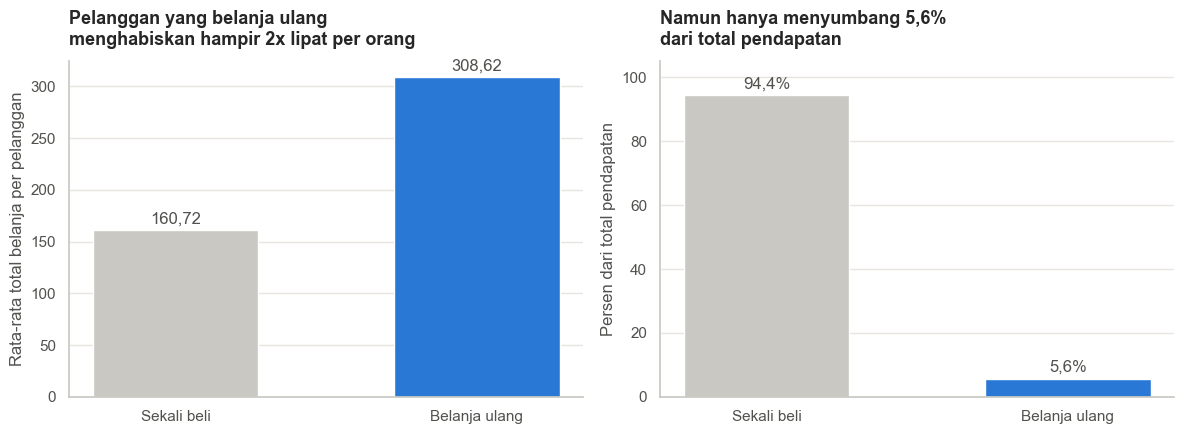

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

customer_labels = customer_type_df.index.astype(str)

bars = axes[0].bar(customer_labels, customer_type_df["rata_rata_belanja"], color=[MUTED, HIGHLIGHT], width=0.55)
axes[0].bar_label(bars, labels=[format_number(v, 2) for v in customer_type_df["rata_rata_belanja"]], padding=3, color=TEXT)
axes[0].set_title("Pelanggan yang belanja ulang\nmenghabiskan hampir 2x lipat per orang")
axes[0].set_ylabel("Rata-rata total belanja per pelanggan")
axes[0].grid(axis="y", color=GRID)
axes[0].set_axisbelow(True)

bars = axes[1].bar(customer_labels, customer_type_df["persen_pendapatan"], color=[MUTED, HIGHLIGHT], width=0.55)
axes[1].bar_label(bars, labels=[f"{format_number(v, 1)}%" for v in customer_type_df["persen_pendapatan"]], padding=3, color=TEXT)
axes[1].set_title("Namun hanya menyumbang 5,6%\ndari total pendapatan")
axes[1].set_ylabel("Persen dari total pendapatan")
axes[1].set_ylim(0, 105)
axes[1].grid(axis="y", color=GRID)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

**Insight:**
- **Repeat rate selama Januari 2017 – Agustus 2018 hanya 3,00%**: dari 93.104 pelanggan, hanya 2.789 yang belanja lebih dari sekali. Sebanyak 97% pelanggan hanya belanja 1 kali, dan yang belanja 3 kali atau lebih hanya 227 pelanggan (0,24%).
- Pelanggan yang belanja ulang rata-rata menghabiskan 308,62, hampir 2 kali lipat pelanggan sekali beli (160,72). Namun karena jumlahnya sangat sedikit, kontribusi mereka hanya 5,6% dari total pendapatan.
- Pendapatan hampir seluruhnya bergantung pada pelanggan baru yang belanja sekali lalu tidak kembali. Ini menegaskan bahwa retensi adalah masalah serius, sekaligus peluang: setiap pelanggan yang berhasil diajak belanja ulang bernilai hampir 2 kali lipat.

### Pertanyaan 2: Metode pembayaran apa yang paling banyak digunakan, dan apakah pembayaran cicilan kartu kredit memiliki rata-rata nilai transaksi lebih tinggi dibanding kartu kredit 1x?

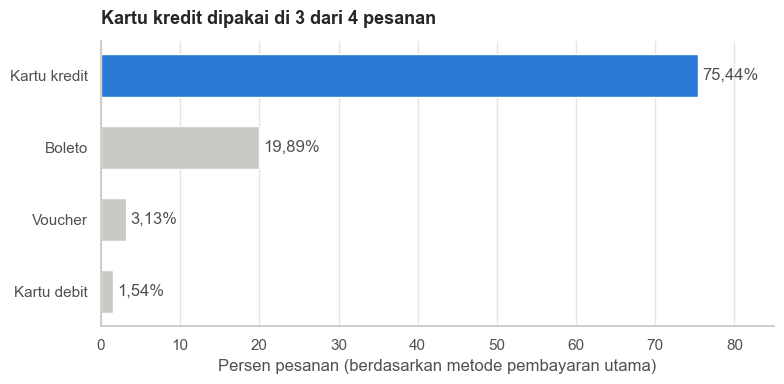

In [89]:
method_plot_df = payment_method_df.sort_values("persen_pesanan")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(
    method_plot_df.index.map(payment_type_labels),
    method_plot_df["persen_pesanan"],
    color=[HIGHLIGHT if method == "credit_card" else MUTED for method in method_plot_df.index],
    height=0.6,
)
ax.bar_label(bars, labels=[f"{format_number(v, 2)}%" for v in method_plot_df["persen_pesanan"]], padding=3, color=TEXT)
ax.set_title("Kartu kredit dipakai di 3 dari 4 pesanan")
ax.set_xlabel("Persen pesanan (berdasarkan metode pembayaran utama)")
ax.set_xlim(0, 85)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

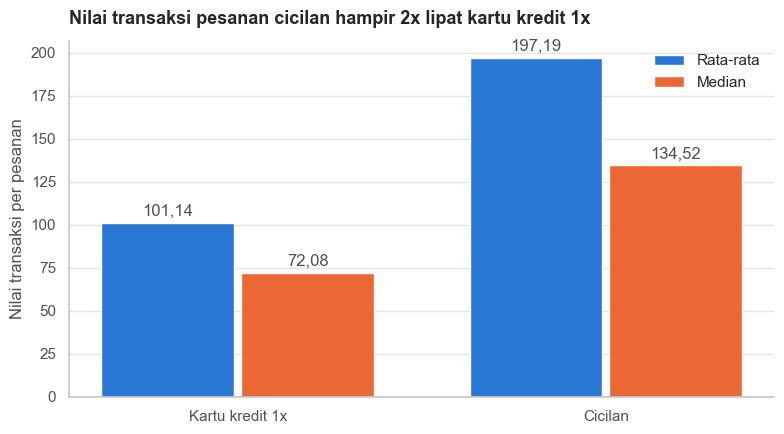

In [90]:
group_plot_df = credit_card_group_df[["rata_rata_nilai", "median_nilai"]]
x = np.arange(len(group_plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
mean_bars = ax.bar(x - width / 2 - 0.01, group_plot_df["rata_rata_nilai"], width, color=HIGHLIGHT, label="Rata-rata")
median_bars = ax.bar(x + width / 2 + 0.01, group_plot_df["median_nilai"], width, color=SECOND, label="Median")
for container in [mean_bars, median_bars]:
    ax.bar_label(container, labels=[format_number(v, 2) for v in container.datavalues], padding=3, color=TEXT)
ax.set_xticks(x, group_plot_df.index.astype(str))
ax.set_title("Nilai transaksi pesanan cicilan hampir 2x lipat kartu kredit 1x")
ax.set_ylabel("Nilai transaksi per pesanan")
ax.legend(frameon=False)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Grafik berikut hanya menampilkan cicilan **1x sampai 10x**. Setiap jumlah cicilan dalam rentang ini memiliki lebih dari 600 pesanan, sehingga rata-rata dan mediannya cukup stabil. Cicilan 11x ke atas hanya memiliki 1–128 pesanan per jumlah cicilan, sehingga garisnya akan naik-turun tajam karena segelintir pesanan dan bisa menyesatkan. Data lengkapnya tetap tersedia di tabel EDA (`installments_df`).

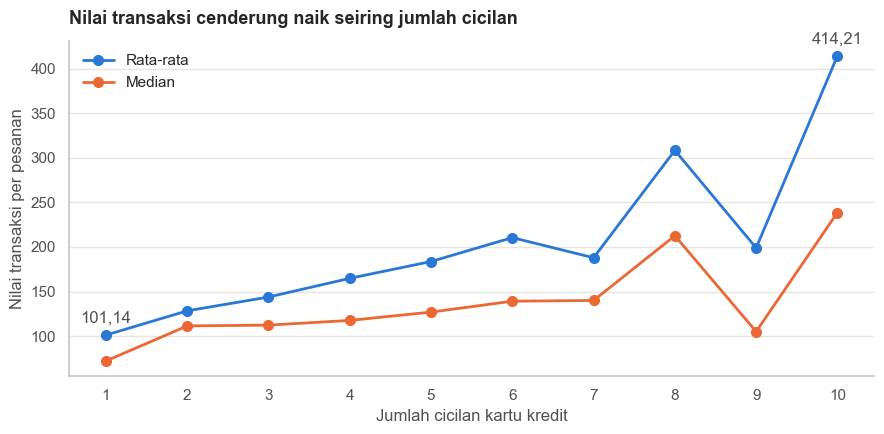

In [91]:
installments_plot_df = installments_df.loc[1:10]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(installments_plot_df.index, installments_plot_df["rata_rata_nilai"], color=HIGHLIGHT, linewidth=2, marker="o", markersize=7, label="Rata-rata")
ax.plot(installments_plot_df.index, installments_plot_df["median_nilai"], color=SECOND, linewidth=2, marker="o", markersize=7, label="Median")
for installment in [1, 10]:
    value = installments_plot_df.loc[installment, "rata_rata_nilai"]
    ax.annotate(format_number(value, 2), (installment, value), textcoords="offset points", xytext=(0, 9), ha="center", color=TEXT)
ax.set_xticks(installments_plot_df.index)
ax.set_title("Nilai transaksi cenderung naik seiring jumlah cicilan")
ax.set_xlabel("Jumlah cicilan kartu kredit")
ax.set_ylabel("Nilai transaksi per pesanan")
ax.legend(frameon=False)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

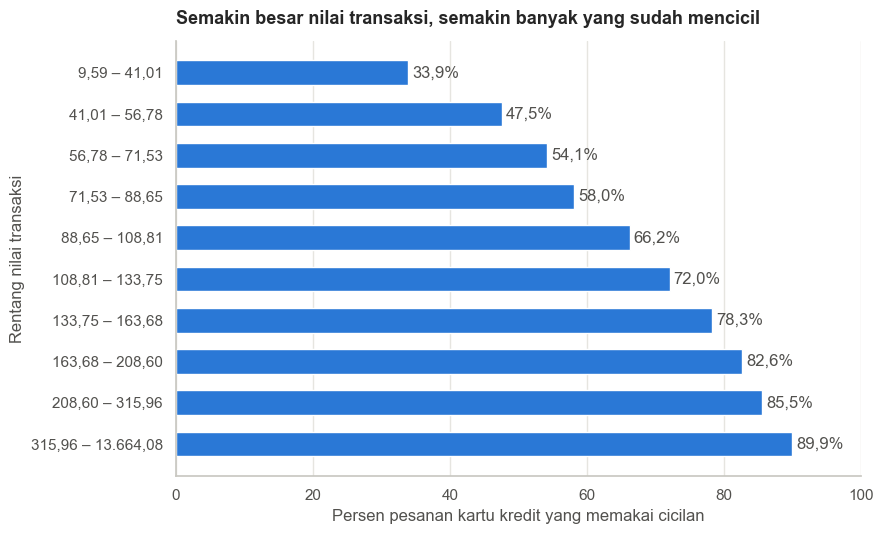

In [92]:
share_labels = [
    f"{format_number(interval.left, 2)} – {format_number(interval.right, 2)}"
    for interval in value_bins.cat.categories
]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(share_labels[::-1], installment_share_df["persen_cicilan"].iloc[::-1], color=HIGHLIGHT, height=0.6)
ax.bar_label(bars, labels=[f"{format_number(v, 1)}%" for v in installment_share_df["persen_cicilan"].iloc[::-1]], padding=3, color=TEXT)
ax.set_title("Semakin besar nilai transaksi, semakin banyak yang sudah mencicil")
ax.set_xlabel("Persen pesanan kartu kredit yang memakai cicilan")
ax.set_ylabel("Rentang nilai transaksi")
ax.set_xlim(0, 100)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Insight:**
- **Kartu kredit adalah metode pembayaran yang paling banyak digunakan**, yaitu pada 75,44% pesanan, jauh di atas boleto (19,89%), voucher (3,13%), dan kartu debit (1,54%).
- **Ya, pesanan dengan cicilan kartu kredit memiliki rata-rata nilai transaksi lebih tinggi.** Rata-ratanya 197,19, hampir 2 kali lipat kartu kredit 1x (101,14). Mediannya juga hampir 2 kali lipat (134,52 vs 72,08), sehingga perbedaannya tidak disebabkan oleh segelintir transaksi bernilai sangat besar.
- Nilai transaksi cenderung naik seiring jumlah cicilan, dari 101,14 untuk 1x menjadi 414,21 untuk 10x. Kenaikannya tidak mulus: 8x dan 10x menonjol tinggi, sedangkan 7x dan 9x lebih rendah. 8x dan 10x juga lebih banyak dipilih (4.117 dan 5.103 pesanan) dibanding 7x dan 9x (1.550 dan 615 pesanan).
- Data ini menunjukkan hubungan, bukan sebab-akibat. Belum tentu cicilan yang membuat pelanggan belanja lebih banyak; bisa juga pelanggan memilih cicilan karena barang yang dibeli memang mahal.
- Pada transaksi bernilai di atas 163,68, lebih dari 80% pesanan kartu kredit sudah memakai cicilan. Jika cicilan 0% hanya ditawarkan untuk transaksi bernilai tinggi, sebagian besar penggunanya adalah pelanggan yang memang sudah mencicil. Promo ini lebih berguna sebagai pemancing agar pelanggan menambah nilai belanja sampai batas minimum tertentu.

### Pertanyaan 3: Pada hari dan jam berapa pelanggan paling banyak melakukan pembelian selama Januari 2017 – Agustus 2018?

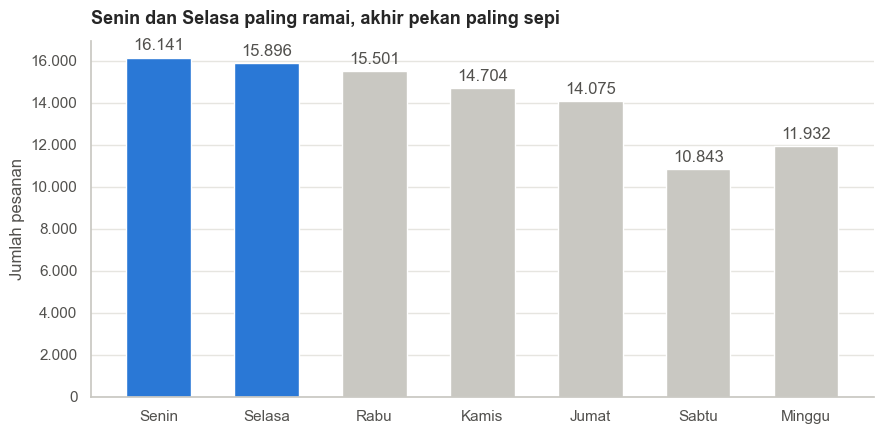

In [93]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(
    orders_by_day_df.index.astype(str),
    orders_by_day_df["jumlah_pesanan"],
    color=[HIGHLIGHT if day in ["Senin", "Selasa"] else MUTED for day in orders_by_day_df.index],
    width=0.6,
)
ax.bar_label(bars, labels=[format_number(v) for v in orders_by_day_df["jumlah_pesanan"]], padding=3, color=TEXT)
ax.set_title("Senin dan Selasa paling ramai, akhir pekan paling sepi")
ax.set_ylabel("Jumlah pesanan")
ax.yaxis.set_major_formatter(thousands_formatter)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

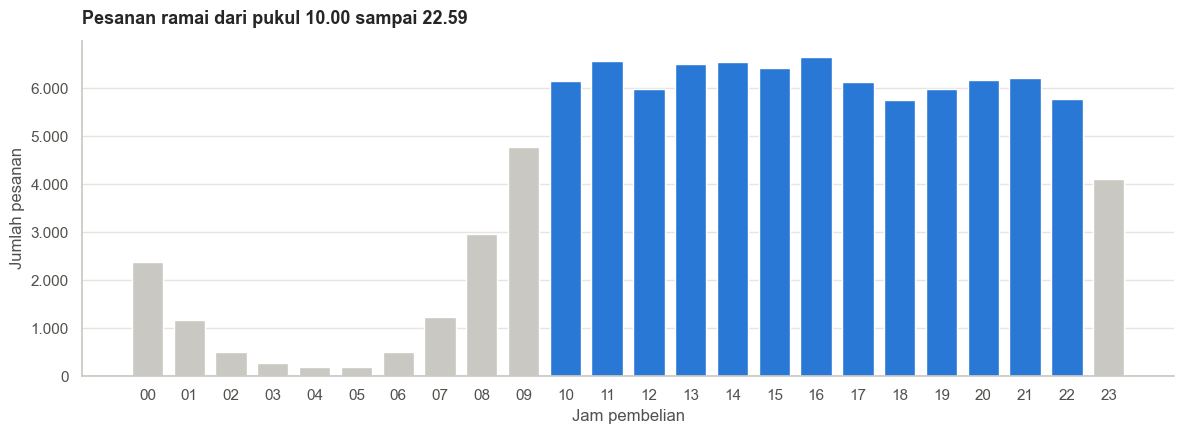

In [94]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(
    orders_by_hour_df.index,
    orders_by_hour_df["jumlah_pesanan"],
    color=[HIGHLIGHT if 10 <= hour <= 22 else MUTED for hour in orders_by_hour_df.index],
    width=0.75,
)
ax.set_xticks(range(24), [f"{hour:02d}" for hour in range(24)])
ax.set_title("Pesanan ramai dari pukul 10.00 sampai 22.59")
ax.set_xlabel("Jam pembelian")
ax.set_ylabel("Jumlah pesanan")
ax.yaxis.set_major_formatter(thousands_formatter)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

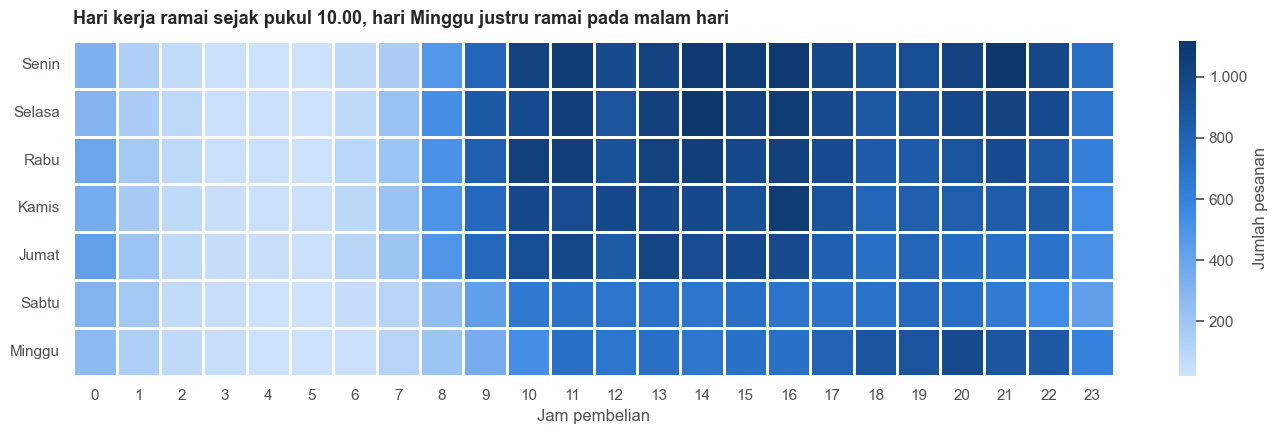

In [95]:
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(
    day_hour_df,
    cmap=BLUE_RAMP,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Jumlah pesanan", "format": thousands_formatter},
    ax=ax,
)
ax.set_title("Hari kerja ramai sejak pukul 10.00, hari Minggu justru ramai pada malam hari")
ax.set_xlabel("Jam pembelian")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

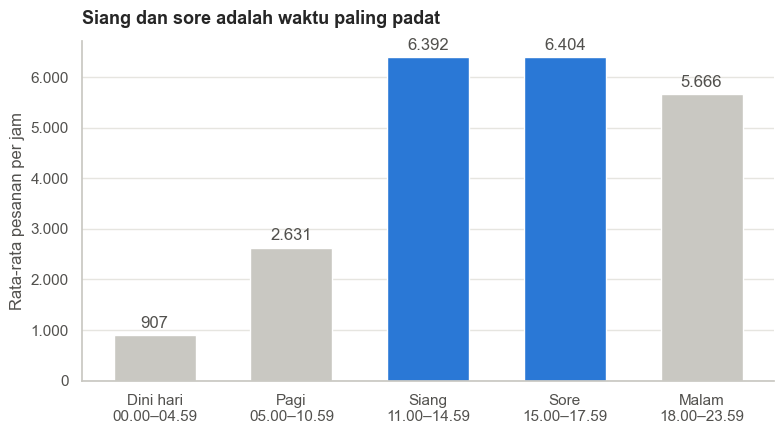

In [96]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    orders_by_time_group_df.index.astype(str),
    orders_by_time_group_df["rata_rata_pesanan_per_jam"],
    color=[HIGHLIGHT if group in ["Siang", "Sore"] else MUTED for group in orders_by_time_group_df.index],
    width=0.6,
)
ax.bar_label(bars, labels=[format_number(v) for v in orders_by_time_group_df["rata_rata_pesanan_per_jam"]], padding=3, color=TEXT)
ax.set_xticks(
    range(len(orders_by_time_group_df)),
    [f"{group}\n{hours}" for group, hours in zip(
        orders_by_time_group_df.index.astype(str),
        ["00.00–04.59", "05.00–10.59", "11.00–14.59", "15.00–17.59", "18.00–23.59"],
    )],
)
ax.set_title("Siang dan sore adalah waktu paling padat")
ax.set_ylabel("Rata-rata pesanan per jam")
ax.yaxis.set_major_formatter(thousands_formatter)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Insight:**
- **Hari paling ramai adalah Senin (16.141 pesanan) dan Selasa (15.896 pesanan).** Jumlah pesanan turun perlahan sampai Jumat, dan akhir pekan paling sepi, terutama Sabtu (10.843 pesanan).
- **Jam paling ramai adalah pukul 10.00–22.59**, dengan puncak pukul 16.00 (6.655 pesanan). Pesanan paling sepi pada pukul 03.00–05.59.
- Jika dihitung rata-rata per jam, kelompok **Sore** (6.404 pesanan per jam) dan **Siang** (6.392) adalah waktu paling padat, diikuti Malam (5.666).
- Heatmap menunjukkan pola yang berbeda di hari Minggu: pesanan justru memuncak pada malam hari (tertinggi pukul 20.00 dengan 967 pesanan), bukan siang hari seperti hari kerja.

### Pertanyaan 4: Di negara bagian mana pelanggan segmen At Risk dan Lost paling banyak?

Visualisasi Pertanyaan 4 (peta dan bar chart) ada di bagian **Analisis Lanjutan**, karena membutuhkan segmen RFM yang baru dibentuk di bagian tersebut.

## Analisis Lanjutan (Opsional)

Teknik analisis lanjutan yang dipakai (tanpa algoritma machine learning):
1. **RFM Analysis**
   - **Tujuan:** mengelompokkan pelanggan berdasarkan perilaku pembeliannya, yaitu seberapa baru terakhir belanja (Recency), seberapa sering belanja (Frequency), dan seberapa besar total belanjanya (Monetary). Hasilnya dipakai untuk menentukan kelompok pelanggan yang perlu diprioritaskan dalam program retensi (Pertanyaan 1).
2. **Clustering dengan binning dan manual grouping**
   - **Tujuan:** mengubah nilai R, F, dan M yang berupa angka menjadi skor dan segmen yang mudah dipahami dan bisa langsung ditindaklanjuti. Binning membagi nilai ke dalam kelompok (`pd.qcut` berdasarkan kuartil untuk R dan M, `pd.cut` untuk F), lalu manual grouping menggabungkan skor-skor tersebut menjadi 6 segmen pelanggan berdasarkan aturan bisnis.
   - Binning juga dipakai di bagian EDA untuk mengelompokkan jam pembelian menjadi 5 kelompok waktu (Pertanyaan 3), serta mengelompokkan pesanan kartu kredit berdasarkan jumlah cicilan dan rentang nilai transaksi (Pertanyaan 2).
3. **Geospatial Analysis**
   - **Tujuan:** melihat sebaran pelanggan At Risk dan Lost berdasarkan lokasi negara bagian di peta (menggunakan folium), sehingga wilayah yang paling perlu diprioritaskan untuk promo retensi bisa ditentukan (Pertanyaan 4).

### RFM Analysis

- **Recency**: jumlah hari dari pembelian terakhir pelanggan sampai tanggal acuan **1 September 2018** (sehari setelah periode analisis berakhir).
- **Frequency**: jumlah pesanan `delivered` pelanggan.
- **Monetary**: total `payment_value` pelanggan.

In [97]:
reference_date = pd.Timestamp("2018-09-01")

rfm_df = main_df.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("total_payment", "sum"),
)
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"]).dt.days
rfm_df = rfm_df[["recency", "frequency", "monetary"]]
rfm_df.head()

,recency,frequency,monetary
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90
0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19
0000f46a3911fa3c0805444483337064,539,1,86.22
0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62
0004aac84e0df4da2b147fca70cf8255,290,1,196.89


In [98]:
rfm_df.describe()

,recency,frequency,monetary
count,93104.000000,93104.000000,93104.000000
mean,238.240097,1.033371,165.147313
std,150.946042,0.209012,226.381578
min,2.000000,1.000000,9.590000
25%,116.000000,1.000000,63.040000
50%,220.000000,1.000000,107.780000
75%,347.000000,1.000000,182.495000
max,603.000000,15.000000,13664.080000


**Pemberian skor (binning):**
- **R score** dan **M score** dibagi menjadi 4 kelompok berdasarkan kuartil. R score 4 berarti pembelian paling baru, dan M score 4 berarti total belanja paling besar.
- **F score** tidak bisa dibagi dengan kuartil karena 97% pelanggan hanya belanja 1 kali, sehingga dibagi manual: 1x = 1, 2x = 2, 3x atau lebih = 3.

In [99]:
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["f_score"] = pd.cut(
    rfm_df["frequency"], bins=[0, 1, 2, rfm_df["frequency"].max()], labels=[1, 2, 3]
).astype(int)
rfm_df.head()

,recency,frequency,monetary,r_score,m_score,f_score
customer_unique_id,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90,4,3,1
0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19,4,1,1
0000f46a3911fa3c0805444483337064,539,1,86.22,1,2,1
0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62,2,1,1
0004aac84e0df4da2b147fca70cf8255,290,1,196.89,2,4,1


Batas nilai tiap skor:

In [100]:
score_ranges_df = pd.concat({
    "recency (hari)": rfm_df.groupby("r_score")["recency"].agg(["min", "max"]),
    "monetary": rfm_df.groupby("m_score")["monetary"].agg(["min", "max"]),
    "frequency": rfm_df.groupby("f_score")["frequency"].agg(["min", "max"]),
}, axis=1)
score_ranges_df

recency (hari)      monetary           frequency      
             min  max      min       max       min   max
1            348  603     9.59     63.04       1.0   1.0
2            221  347    63.05    107.78       2.0   2.0
3            117  220   107.79    182.49       3.0  15.0
4              2  116   182.51  13664.08       NaN   NaN

**Segmentasi pelanggan (manual grouping).** R tinggi berarti R score 3–4, dan M tinggi berarti M score 3–4.

| Segmen | Aturan | Action |
|---|---|---|
| Best Customers | F score ≥ 2 dan R tinggi | Diberi reward atau program loyalitas |
| At Risk | F score ≥ 2 dan R rendah | Promo win-back (prioritas utama karena dulu pelanggan setia) |
| Potential Loyalist | F score = 1, R tinggi, M tinggi | Didorong supaya belanja kedua kalinya |
| New Customers | F score = 1, R tinggi, M rendah | Promo onboarding |
| Hibernating | F score = 1, R rendah, M tinggi | Promo untuk menarik kembali |
| Lost | F score = 1, R rendah, M rendah | Promo murah, prioritas rendah |

In [101]:
segment_order = ["Best Customers", "At Risk", "Potential Loyalist", "New Customers", "Hibernating", "Lost"]

is_repeat = rfm_df["f_score"] >= 2
is_recent = rfm_df["r_score"] >= 3
is_high_value = rfm_df["m_score"] >= 3

rfm_df["segment"] = pd.Categorical(
    np.select(
        [
            is_repeat & is_recent,
            is_repeat & ~is_recent,
            ~is_repeat & is_recent & is_high_value,
            ~is_repeat & is_recent & ~is_high_value,
            ~is_repeat & ~is_recent & is_high_value,
        ],
        segment_order[:5],
        default="Lost",
    ),
    categories=segment_order,
    ordered=True,
)
rfm_df.head()

,recency,frequency,monetary,r_score,m_score,f_score,segment
customer_unique_id,,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,113,1,141.90,4,3,1,Potential Loyalist
0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,27.19,4,1,1,New Customers
0000f46a3911fa3c0805444483337064,539,1,86.22,1,2,1,Lost
0000f6ccb0745a6a4b88665a16c9f078,323,1,43.62,2,1,1,Lost
0004aac84e0df4da2b147fca70cf8255,290,1,196.89,2,4,1,Hibernating


In [102]:
segment_summary_df = rfm_df.groupby("segment", observed=True).agg(
    jumlah_pelanggan=("recency", "size"),
    rata_rata_recency=("recency", "mean"),
    rata_rata_frequency=("frequency", "mean"),
    rata_rata_monetary=("monetary", "mean"),
    total_monetary=("monetary", "sum"),
)
segment_summary_df["persen_pelanggan"] = segment_summary_df["jumlah_pelanggan"] / segment_summary_df["jumlah_pelanggan"].sum() * 100
segment_summary_df["persen_pendapatan"] = segment_summary_df["total_monetary"] / segment_summary_df["total_monetary"].sum() * 100
segment_summary_df.round(2)

,jumlah_pelanggan,rata_rata_recency,rata_rata_frequency,rata_rata_monetary,total_monetary,persen_pelanggan,persen_pendapatan
segment,,,,,,,
Best Customers,1539,114.04,2.14,314.96,484717.25,1.65,3.15
At Risk,1250,352.95,2.08,300.83,376037.31,1.34,2.45
Potential Loyalist,22477,113.18,1.00,261.22,5871488.92,24.14,38.19
New Customers,22664,113.37,1.00,63.01,1428135.55,24.34,9.29
Hibernating,21611,363.93,1.00,264.27,5711177.54,23.21,37.14
Lost,23563,364.39,1.00,63.84,1504318.87,25.31,9.78


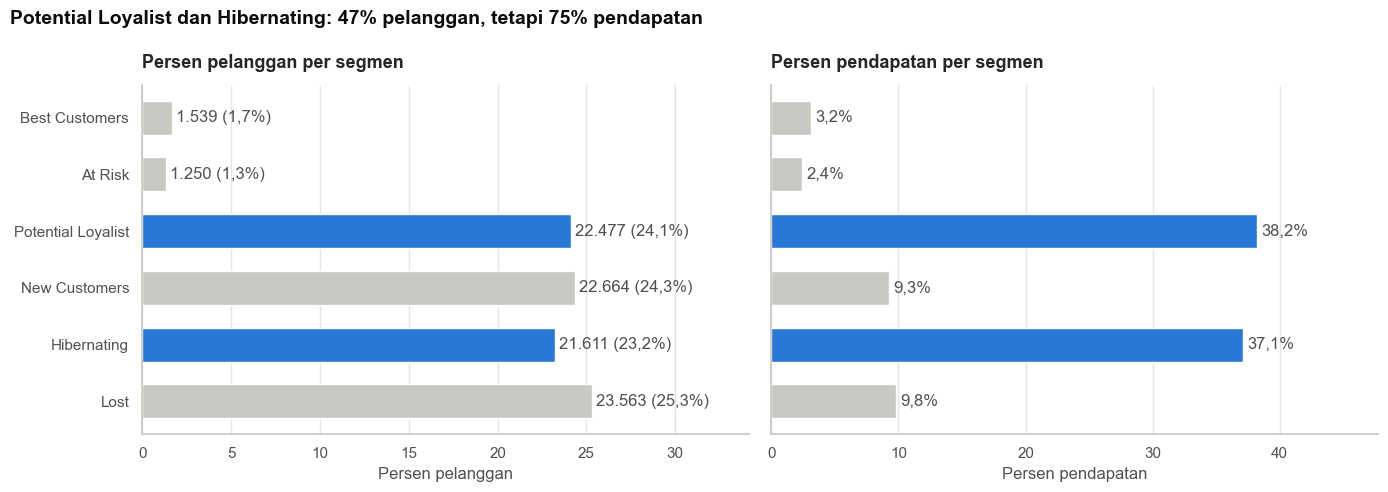

In [103]:
segment_plot_df = segment_summary_df.iloc[::-1]
priority_colors = [HIGHLIGHT if segment in ["Potential Loyalist", "Hibernating"] else MUTED for segment in segment_plot_df.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

bars = axes[0].barh(segment_plot_df.index.astype(str), segment_plot_df["persen_pelanggan"], color=priority_colors, height=0.6)
axes[0].bar_label(
    bars,
    labels=[f"{format_number(n)} ({format_number(p, 1)}%)" for n, p in zip(segment_plot_df["jumlah_pelanggan"], segment_plot_df["persen_pelanggan"])],
    padding=3,
    color=TEXT,
)
axes[0].set_title("Persen pelanggan per segmen")
axes[0].set_xlabel("Persen pelanggan")
axes[0].set_xlim(0, segment_plot_df["persen_pelanggan"].max() * 1.35)

bars = axes[1].barh(segment_plot_df.index.astype(str), segment_plot_df["persen_pendapatan"], color=priority_colors, height=0.6)
axes[1].bar_label(bars, labels=[f"{format_number(v, 1)}%" for v in segment_plot_df["persen_pendapatan"]], padding=3, color=TEXT)
axes[1].set_title("Persen pendapatan per segmen")
axes[1].set_xlabel("Persen pendapatan")
axes[1].set_xlim(0, segment_plot_df["persen_pendapatan"].max() * 1.25)

for ax in axes:
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)

fig.suptitle(
    "Potential Loyalist dan Hibernating: 47% pelanggan, tetapi 75% pendapatan",
    x=0.01, ha="left", fontsize=14, fontweight="bold", color="#0b0b0b",
)
plt.tight_layout()
plt.show()

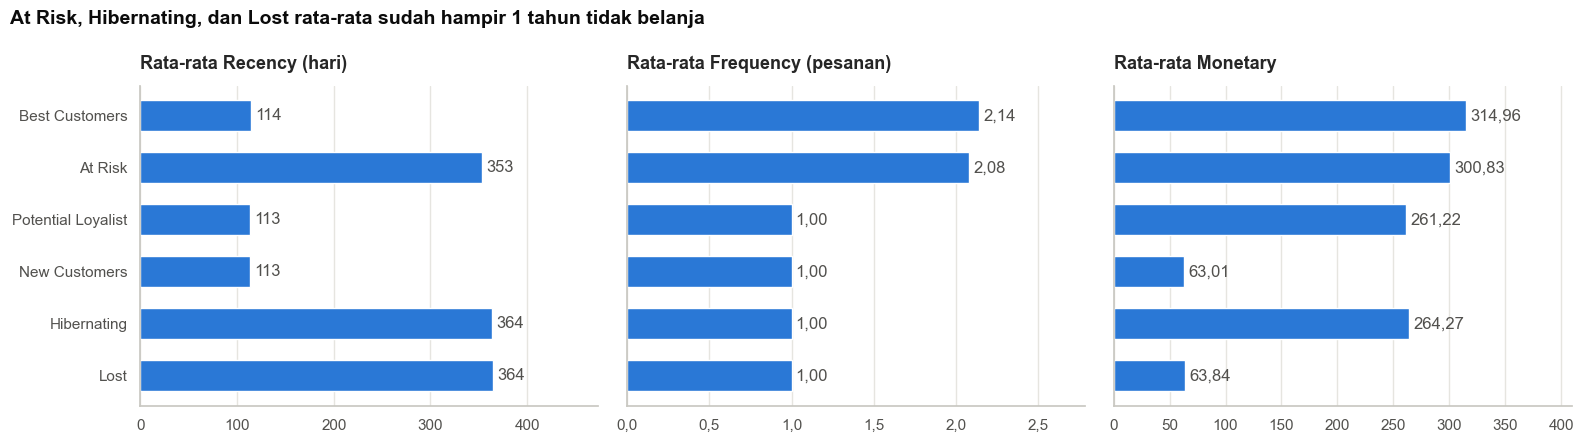

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
metrics = [
    ("rata_rata_recency", "Rata-rata Recency (hari)", 0, 0),
    ("rata_rata_frequency", "Rata-rata Frequency (pesanan)", 2, 1),
    ("rata_rata_monetary", "Rata-rata Monetary", 2, 0),
]

for ax, (column, title, label_decimals, tick_decimals) in zip(axes, metrics):
    bars = ax.barh(segment_plot_df.index.astype(str), segment_plot_df[column], color=HIGHLIGHT, height=0.6)
    ax.bar_label(bars, labels=[format_number(v, label_decimals) for v in segment_plot_df[column]], padding=3, color=TEXT)
    ax.set_title(title)
    ax.set_xlim(0, segment_plot_df[column].max() * 1.3)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _, d=tick_decimals: format_number(value, d)))
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)

fig.suptitle(
    "At Risk, Hibernating, dan Lost rata-rata sudah hampir 1 tahun tidak belanja",
    x=0.01, ha="left", fontsize=14, fontweight="bold", color="#0b0b0b",
)
plt.tight_layout()
plt.show()

**Insight:**
- Batas skor dari kuartil: R score 4 = belanja terakhir 2–116 hari sebelum tanggal acuan, R score 1 = 348–603 hari. M score 1 = total belanja 9,59–63,04, M score 4 = 182,51–13.664,08.
- **Best Customers** hanya 1.539 pelanggan (1,65%) dengan kontribusi 3,15% pendapatan, tetapi rata-rata belanjanya paling tinggi (314,96) dan mereka rata-rata sudah belanja 2,14 kali.
- **At Risk** berjumlah 1.250 pelanggan (1,34%). Dulu mereka belanja ulang dengan rata-rata nilai tinggi (300,83), tetapi rata-rata sudah 353 hari tidak belanja.
- **Lost** adalah segmen terbesar, yaitu 23.563 pelanggan (25,31%), tetapi nilainya paling kecil (rata-rata 63,84) dan hanya menyumbang 9,78% pendapatan.
- Temuan penting di luar At Risk dan Lost: **Potential Loyalist** (38,19% pendapatan) dan **Hibernating** (37,14% pendapatan) bersama-sama mencakup 47% pelanggan tetapi menyumbang sekitar 75% pendapatan. Hibernating juga sudah rata-rata 364 hari tidak belanja, sehingga ikut berisiko hilang.
- At Risk, Hibernating, dan Lost rata-rata sudah 353–364 hari (hampir 1 tahun) tidak belanja, sedangkan Best Customers, Potential Loyalist, dan New Customers rata-rata baru 113–114 hari.

### Geospatial Analysis (Pertanyaan 4)

Menghitung jumlah pelanggan At Risk dan Lost di setiap negara bagian, berdasarkan lokasi pesanan terakhir pelanggan (`customer_state_df`):

In [105]:
state_names = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas", "BA": "Bahia",
    "CE": "Ceará", "DF": "Distrito Federal", "ES": "Espírito Santo", "GO": "Goiás",
    "MA": "Maranhão", "MT": "Mato Grosso", "MS": "Mato Grosso do Sul", "MG": "Minas Gerais",
    "PA": "Pará", "PB": "Paraíba", "PR": "Paraná", "PE": "Pernambuco", "PI": "Piauí",
    "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RS": "Rio Grande do Sul",
    "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina", "SP": "São Paulo",
    "SE": "Sergipe", "TO": "Tocantins",
}

rfm_state_df = rfm_df.join(customer_state_df)

state_segment_df = rfm_state_df.groupby("customer_state").agg(
    jumlah_pelanggan=("segment", "size"),
    at_risk=("segment", lambda s: (s == "At Risk").sum()),
    lost=("segment", lambda s: (s == "Lost").sum()),
)
state_segment_df["at_risk_lost"] = state_segment_df["at_risk"] + state_segment_df["lost"]
state_segment_df["persen_at_risk_lost"] = state_segment_df["at_risk_lost"] / state_segment_df["jumlah_pelanggan"] * 100
state_segment_df["persen_dari_total_at_risk_lost"] = state_segment_df["at_risk_lost"] / state_segment_df["at_risk_lost"].sum() * 100
state_segment_df["nama_negara_bagian"] = state_segment_df.index.map(state_names)
state_segment_df = state_segment_df.join(state_location_df).sort_values("at_risk_lost", ascending=False)
state_segment_df.round(2)

,jumlah_pelanggan,at_risk,lost,at_risk_lost,persen_at_risk_lost,persen_dari_total_at_risk_lost,nama_negara_bagian,lat,lng
customer_state,,,,,,,,,
SP,39059,510,10186,10696,27.38,43.11,São Paulo,-23.50,-46.71
RJ,11877,177,2956,3133,26.38,12.63,Rio de Janeiro,-22.84,-43.26
MG,10963,147,2852,2999,27.36,12.09,Minas Gerais,-19.92,-43.99
RS,5150,73,1351,1424,27.65,5.74,Rio Grande do Sul,-29.76,-51.34
PR,4747,60,1241,1301,27.41,5.24,Paraná,-25.36,-50.74
SC,3438,47,927,974,28.33,3.93,Santa Catarina,-27.09,-49.06
BA,3153,42,742,784,24.87,3.16,Bahia,-12.95,-39.00
ES,1925,32,487,519,26.96,2.09,Espírito Santo,-20.29,-40.34
GO,1887,23,461,484,25.65,1.95,Goiás,-16.68,-49.27


Peta sebaran pelanggan At Risk + Lost. Ukuran lingkaran sebanding dengan jumlah pelanggan At Risk + Lost (luas lingkaran, bukan jari-jarinya). Arahkan kursor ke lingkaran untuk melihat ringkasan, dan klik untuk melihat detailnya.

In [106]:
state_map = folium.Map(location=[-14.5, -52.0], zoom_start=4, tiles="OpenStreetMap")
max_at_risk_lost = state_segment_df["at_risk_lost"].max()

for state, row in state_segment_df.iterrows():
    popup_html = (
        f"<b>{row['nama_negara_bagian']} ({state})</b><br>"
        f"At Risk: {format_number(row['at_risk'])}<br>"
        f"Lost: {format_number(row['lost'])}<br>"
        f"At Risk + Lost: {format_number(row['at_risk_lost'])} "
        f"({format_number(row['persen_at_risk_lost'], 1)}% dari {format_number(row['jumlah_pelanggan'])} pelanggan)"
    )
    folium.CircleMarker(
        location=[row["lat"], row["lng"]],
        radius=3 + 37 * np.sqrt(row["at_risk_lost"] / max_at_risk_lost),
        color="white",
        weight=1,
        fill=True,
        fill_color=HIGHLIGHT,
        fill_opacity=0.65,
        tooltip=f"{state}: {format_number(row['at_risk_lost'])} pelanggan At Risk + Lost",
        popup=folium.Popup(popup_html, max_width=300),
    ).add_to(state_map)

state_map

Bar chart 10 negara bagian dengan pelanggan At Risk + Lost terbanyak (pendamping peta, karena peta folium tidak tampil jika notebook dibuka di GitHub):

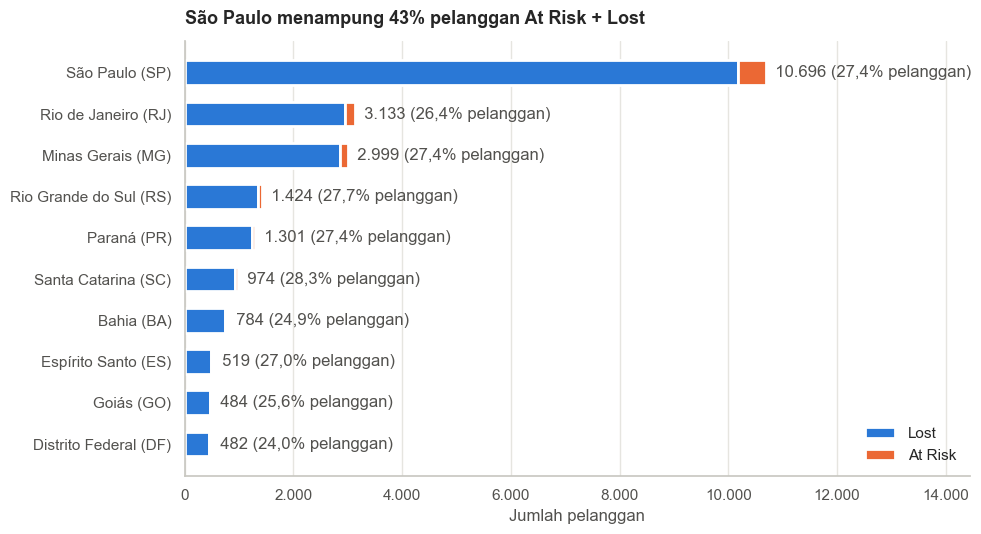

In [107]:
top_states_df = state_segment_df.head(10).iloc[::-1]
state_labels = [f"{state_names[state]} ({state})" for state in top_states_df.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(state_labels, top_states_df["lost"], color=HIGHLIGHT, height=0.6, label="Lost", edgecolor="white", linewidth=2)
ax.barh(state_labels, top_states_df["at_risk"], left=top_states_df["lost"], color=SECOND, height=0.6, label="At Risk", edgecolor="white", linewidth=2)
for y, (total, percent) in enumerate(zip(top_states_df["at_risk_lost"], top_states_df["persen_at_risk_lost"])):
    ax.text(total, y, f"  {format_number(total)} ({format_number(percent, 1)}% pelanggan)", va="center", color=TEXT)
ax.set_title("São Paulo menampung 43% pelanggan At Risk + Lost")
ax.set_xlabel("Jumlah pelanggan")
ax.set_xlim(0, top_states_df["at_risk_lost"].max() * 1.35)
ax.xaxis.set_major_formatter(thousands_formatter)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Insight:**
- Total pelanggan At Risk + Lost ada 24.813 orang, dan hampir semuanya (23.563) berasal dari segmen Lost.
- **Negara bagian dengan pelanggan At Risk + Lost terbanyak adalah São Paulo (SP) dengan 10.696 pelanggan**, atau 43,11% dari seluruh pelanggan At Risk + Lost. Urutan berikutnya adalah Rio de Janeiro (RJ, 3.133 pelanggan) dan Minas Gerais (MG, 2.999 pelanggan). Ketiganya mencakup 67,83% dari seluruh pelanggan At Risk + Lost.
- Peta menunjukkan pelanggan At Risk + Lost terpusat di wilayah tenggara dan selatan Brasil, sedangkan wilayah utara dan tengah hanya memiliki sedikit.
- Persentase pelanggan At Risk + Lost di dalam tiap negara bagian hampir sama, yaitu sekitar 24–28% di 10 negara bagian teratas. Jadi SP berada di urutan pertama karena jumlah pelanggannya paling banyak, bukan karena retensi di SP lebih buruk dibanding wilayah lain.
- Negara bagian kecil seperti Roraima (RR) memiliki persentase tertinggi (30,77%), tetapi jumlahnya hanya 12 dari 39 pelanggan, sehingga angka ini kurang bisa diandalkan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Januari 2017 – Agustus 2018, hanya **3,00%** pelanggan (2.789 dari 93.104) yang belanja lebih dari sekali, sehingga retensi adalah masalah serius. Segmentasi RFM menghasilkan 6 segmen:

  | Segmen | Jumlah pelanggan | Persen pelanggan | Persen pendapatan |
  |---|---|---|---|
  | Lost | 23.563 | 25,31% | 9,78% |
  | New Customers | 22.664 | 24,34% | 9,29% |
  | Potential Loyalist | 22.477 | 24,14% | 38,19% |
  | Hibernating | 21.611 | 23,21% | 37,14% |
  | Best Customers | 1.539 | 1,65% | 3,15% |
  | At Risk | 1.250 | 1,34% | 2,45% |

  Kelompok yang perlu diprioritaskan dalam program retensi:
  1. **At Risk**: dulu pelanggan setia dengan nilai belanja tinggi (rata-rata 300,83), tetapi sudah hampir 1 tahun tidak belanja. Jumlahnya sedikit, sehingga bisa dijangkau secara personal.
  2. **Potential Loyalist dan Hibernating**: bersama-sama mencakup 47% pelanggan, tetapi menyumbang sekitar 75% pendapatan.
  3. **Best Customers**: perlu dipertahankan dengan reward karena rata-rata belanjanya paling tinggi (314,96).
  4. **Lost**: jumlahnya paling besar, tetapi nilainya paling kecil (rata-rata 63,84), sehingga prioritasnya rendah.
- **Conclusion pertanyaan 2:** Kartu kredit adalah metode pembayaran yang paling banyak digunakan (**75,44%** pesanan). Pesanan dengan cicilan kartu kredit memiliki rata-rata nilai transaksi **197,19**, hampir 2 kali lipat kartu kredit 1x (**101,14**); mediannya pun hampir 2 kali lipat (134,52 vs 72,08). Semakin besar nilai transaksi, semakin banyak pelanggan yang sudah memilih cicilan: dari 33,91% pada transaksi terkecil sampai 89,88% pada transaksi terbesar. Namun ini hubungan, bukan sebab-akibat: bisa jadi pelanggan memilih cicilan karena barang yang dibeli memang mahal.
- **Conclusion pertanyaan 3:** Pesanan paling banyak terjadi pada hari **Senin (16,29%) dan Selasa (16,04%)**, dan paling sedikit pada hari Sabtu (10,94%). Jam paling ramai adalah **pukul 10.00–22.59** dengan puncak pukul 16.00; jika dihitung rata-rata per jam, kelompok **Siang dan Sore** paling padat. Hari Minggu memiliki pola berbeda, yaitu paling ramai pada malam hari dengan puncak pukul 20.00.
- **Conclusion pertanyaan 4:** Pelanggan At Risk + Lost paling banyak berada di **São Paulo (10.696 pelanggan, 43,11%)**, diikuti Rio de Janeiro (3.133) dan Minas Gerais (2.999). Ketiganya mencakup 67,83% dari seluruh pelanggan At Risk + Lost. Persentase At Risk + Lost di dalam tiap negara bagian mirip (sekitar 24–28%), sehingga SP berada di urutan pertama karena jumlah pelanggannya paling banyak, bukan karena retensinya lebih buruk.

**Rekomendasi Action Item:**
1. **Jalankan program retensi berdasarkan segmen RFM:**
   - **Best Customers**: program poin atau loyalitas, serta akses lebih awal ke promo.
   - **At Risk**: kampanye win-back personal dengan voucher bernilai cukup besar, karena nilai mereka tinggi dan jumlahnya sedikit.
   - **Potential Loyalist**: voucher untuk pembelian kedua, dikirim selagi mereka baru saja belanja (rata-rata 113 hari lalu).
   - **Hibernating**: promo win-back untuk menarik mereka kembali sebelum benar-benar hilang.
   - **Lost**: promo massal berbiaya rendah, misalnya email otomatis.
2. **Uji promo cicilan 0% dengan minimum belanja 182,51** untuk pilihan cicilan 8x–10x yang paling banyak dipakai. Angka 182,51 adalah batas bawah M score 4 pada analisis RFM dan hanya menjadi acuan awal; batas final perlu ditentukan tim bisnis berdasarkan biaya bunga yang ditanggung toko dan margin produk. Karena lebih dari 80% transaksi bernilai tinggi sudah memakai cicilan, promo ini sebaiknya dipakai sebagai pemancing agar pelanggan menambah nilai belanja sampai batas minimum. Jalankan dulu sebagai uji coba (A/B test) dan ukur kenaikan nilai belanja, karena data saat ini belum membuktikan bahwa cicilan menyebabkan nilai belanja naik.
3. **Atur jadwal push notification, flash sale, dan iklan** pada hari Senin–Selasa pukul 11.00–17.59 (kelompok Siang dan Sore). Khusus hari Minggu, jadwalkan pada pukul 18.00–22.59. Hindari pukul 00.00–07.59 karena paling sepi.
4. **Fokuskan anggaran promo retensi At Risk dan Lost** pertama-tama ke São Paulo, Rio de Janeiro, dan Minas Gerais, karena ketiganya sudah mencakup sekitar dua pertiga pelanggan At Risk + Lost. Isi kampanyenya tidak perlu dibedakan per wilayah karena masalah retensinya merata.

## Menyimpan Data untuk Dashboard

Data yang dipakai dashboard disimpan ke `dashboard/main_data.csv`, dengan satu baris per pesanan dalam periode Januari 2017 – Agustus 2018:
- Semua status pesanan disimpan karena Pertanyaan 3 memakai semua status. Dashboard akan memfilter `order_status == "delivered"` untuk Pertanyaan 1, 2, dan 4.
- Kolom pembayaran (`total_payment`, `main_payment_type`, `credit_card_installments`, `credit_card_group`) hanya terisi untuk pesanan `delivered`, sesuai hasil cleaning.
- Kolom `lat` dan `lng` berisi posisi negara bagian pelanggan untuk peta.

In [108]:
dashboard_df = (
    orders_all_status_df[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]]
    .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(order_payments_df, left_on="order_id", right_index=True, how="left")
    .merge(state_location_df, left_on="customer_state", right_index=True, how="left")
    .drop(columns="customer_id")
)

print("Jumlah baris:", len(dashboard_df))
dashboard_df.head()

Jumlah baris: 99092


,order_id,order_status,order_purchase_timestamp,customer_unique_id,customer_state,total_payment,main_payment_type,credit_card_installments,credit_card_group,lat,lng
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,SP,38.71,voucher,1.0,Kartu kredit 1x,-23.503231,-46.707598
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,BA,141.46,boleto,NaN,NaN,-12.948131,-38.998427
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,GO,179.12,credit_card,3.0,Cicilan,-16.677822,-49.267274
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,RN,72.20,credit_card,1.0,Kartu kredit 1x,-5.830698,-35.270867
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,SP,28.62,credit_card,1.0,Kartu kredit 1x,-23.503231,-46.707598


In [109]:
dashboard_df.to_csv("dashboard/main_data.csv", index=False)